In [1]:

# TECH CHALLENGE - FASE 1
# ETAPA 5 - Treinamento dos modelos

from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Definir os nomes das caracteristicas

caracteristicas = [
    "radius", "texture", "perimeter", "area",
    "smoothness", "compactness", "concavity",
    "concave_points", "symmetry", "fractal_dimension"
]

medidas = ["mean", "se", "worst"]

colunas = ["id", "diagnosis"]

for medida in medidas:
    for caracteristica in caracteristicas:
        colunas.append(f"{caracteristica}_{medida}")

# 2. Localizar o dataset

raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

arquivo = raiz / "data" / "raw" / "wdbc.data"

if not arquivo.is_file():
    raise FileNotFoundError("Dataset nao encontrado!")

# 3. Carregar os dados

df = pd.read_csv(
    arquivo,
    header=None,
    names=colunas
)

# 4. Separar as caracteristicas e o diagnostico

X = df.drop(columns=["id", "diagnosis"]).copy()
y = df["diagnosis"].map({"B": 0, "M": 1})

if y.isnull().any():
    raise ValueError("Diagnostico invalido encontrado!")

y = y.astype(int)

# 5. Reproduzir a divisao definida na Etapa 4

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# 6. Verificar as dimensoes

assert X_train.shape == (398, 30)
assert X_val.shape == (85, 30)
assert X_test.shape == (86, 30)

print("=== DADOS PREPARADOS ===")
print("Treinamento:", X_train.shape)
print("Validacao:", X_val.shape)
print("Teste:", X_test.shape)

print("\nPreparacao concluida!")



=== DADOS PREPARADOS ===
Treinamento: (398, 30)
Validacao: (85, 30)
Teste: (86, 30)

Preparacao concluida!


In [2]:

# ETAPA 5 - Treinamento da Regressao Logistica

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.utils.validation import check_is_fitted

print("=== TREINAMENTO DA REGRESSAO LOGISTICA ===")

# 1. Criar o pipeline
pipeline_logistica = Pipeline(
    steps=[
        ("padronizacao", StandardScaler()),
        ("classificador", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]
)

# 2. Treinar somente com os dados de treinamento
pipeline_logistica.fit(X_train, y_train)

# 3. Recuperar o classificador treinado
classificador = pipeline_logistica.named_steps[
    "classificador"
]

# 4. Confirmar que o treinamento ocorreu
check_is_fitted(classificador)

# 5. Verificar caracteristicas aprendidas
print("\nTreinamento concluido!")

print("Caracteristicas utilizadas:",
      classificador.n_features_in_)

print("Classes reconhecidas:",
      classificador.classes_)

print("Quantidade de coeficientes:",
      classificador.coef_.shape[1])

print("Iteracoes realizadas:",
      classificador.n_iter_[0])

# 6. Validar os resultados estruturais
assert classificador.n_features_in_ == 30
assert list(classificador.classes_) == [0, 1]
assert classificador.coef_.shape == (1, 30)

print("\nModelo treinado e estrutura validada!")


=== TREINAMENTO DA REGRESSAO LOGISTICA ===

Treinamento concluido!
Caracteristicas utilizadas: 30
Classes reconhecidas: [0 1]
Quantidade de coeficientes: 30
Iteracoes realizadas: 19

Modelo treinado e estrutura validada!


### Treinamento inicial da Regressão Logística

Foi definida a Regressão Logística como primeiro algoritmo supervisionado a ser treinado no Tech Challenge.

O modelo utiliza as 30 características morfológicas do Breast Cancer Wisconsin Diagnostic e foi organizado em um pipeline contendo o StandardScaler e o classificador LogisticRegression.

O treinamento foi planejado exclusivamente com as 398 amostras destinadas a essa finalidade. A padronização é ajustada internamente pelo pipeline com os dados de treinamento, evitando a utilização de informações dos conjuntos de validação e teste durante o ajuste.

O classificador utiliza regularização padrão e limite de 2.000 iterações. Após o treinamento, serão verificados os atributos internos do estimador e, posteriormente, seu desempenho preditivo será avaliado em dados não utilizados no ajuste.

## Primeiras previsões da Regressão Logística

Nesta etapa, o modelo treinado será aplicado às
85 amostras do conjunto de validação.

Serão obtidas as classes previstas e as
probabilidades estimadas de malignidade.

Os resultados serão comparados posteriormente
com os diagnósticos conhecidos para avaliar
o desempenho do classificador.

In [3]:

# ETAPA 5 - Primeiras previsoes da Regressao Logistica

import numpy as np
import pandas as pd

print("=== PREVISOES NA VALIDACAO ===")

# 1. Gerar previsoes para as 85 amostras
previsoes_val = pipeline_logistica.predict(X_val)

# 2. Obter probabilidades estimadas
probabilidades_val = pipeline_logistica.predict_proba(
    X_val
)

# 3. Identificar a coluna referente a classe maligna
classes = pipeline_logistica.named_steps[
    "classificador"
].classes_

indice_maligno = list(classes).index(1)

probabilidades_maligno = probabilidades_val[
    :, indice_maligno
]

# 4. Organizar os resultados em uma tabela
resultados_val = pd.DataFrame({
    "Diagnostico real": y_val.to_numpy(),
    "Diagnostico previsto": previsoes_val,
    "Probabilidade maligno (%)": (
        probabilidades_maligno * 100
    ).round(2)
}, index=X_val.index)

# 5. Mostrar os primeiros resultados
print("\nPrimeiras 10 previsoes:")
display(resultados_val.head(10))

# 6. Verificar as dimensoes
print("\nTotal de previsoes:", len(previsoes_val))

print("\nClasses previstas:")
print(pd.Series(previsoes_val).value_counts().sort_index())

# 7. Validacoes
assert len(previsoes_val) == len(y_val) == 85
assert probabilidades_val.shape == (85, 2)

assert np.allclose(
    probabilidades_val.sum(axis=1), 1
)

assert np.all(
    (probabilidades_maligno >= 0) &
    (probabilidades_maligno <= 1)
)

print("\nPrevisoes geradas e validadas com sucesso!")


=== PREVISOES NA VALIDACAO ===

Primeiras 10 previsoes:


,Diagnostico real,Diagnostico previsto,Probabilidade maligno (%)
130,0,0,0.06
267,0,0,0.77
385,1,1,84.50
83,1,1,99.84
399,0,0,0.21
107,0,0,0.43
147,0,0,0.49
448,0,0,11.34
139,0,0,0.01
523,0,0,7.56



Total de previsoes: 85

Classes previstas:
0    56
1    29
Name: count, dtype: int64

Previsoes geradas e validadas com sucesso!


## Avaliação inicial — Matriz de confusão

Nesta etapa, será construída a matriz de confusão
da Regressão Logística utilizando as 85 amostras
do conjunto de validação.

O objetivo é identificar os verdadeiros positivos,
verdadeiros negativos, falsos positivos e falsos
negativos.

Será dada atenção especial aos falsos negativos
da classe maligna.

In [4]:

# ETAPA 5 - Matriz de confusao da Regressao Logistica

from sklearn.metrics import confusion_matrix

print("=== MATRIZ DE CONFUSAO - REGRESSAO LOGISTICA ===")

# 1. Calcular a matriz utilizando as amostras
# do conjunto de validacao
matriz_confusao_logistica = confusion_matrix(
    y_val,
    previsoes_val,
    labels=[0, 1]
)

# 2. Exibir a matriz
print("\nMatriz de confusao:")
print(matriz_confusao_logistica)

# 3. Separar os quatro resultados
vn, fp, fn, vp = matriz_confusao_logistica.ravel()

# 4. Apresentar os resultados
print("\n=== INTERPRETACAO ===")

print("Verdadeiros negativos:", vn)
print("Falsos positivos:", fp)
print("Falsos negativos:", fn)
print("Verdadeiros positivos:", vp)

# 5. Verificar o total de amostras
total = vn + fp + fn + vp

print("\nTotal de amostras avaliadas:", total)

assert total == 85

# 6. Verificar a distribuicao real
assert vn + fp == 53  # Benignos
assert fn + vp == 32  # Malignos

print("\nMatriz de confusao validada com sucesso!")


=== MATRIZ DE CONFUSAO - REGRESSAO LOGISTICA ===

Matriz de confusao:
[[53  0]
 [ 3 29]]

=== INTERPRETACAO ===
Verdadeiros negativos: 53
Falsos positivos: 0
Falsos negativos: 3
Verdadeiros positivos: 29

Total de amostras avaliadas: 85

Matriz de confusao validada com sucesso!


## Visualização da matriz de confusão

A matriz de confusão será representada graficamente
para facilitar a interpretação dos erros e acertos
da Regressão Logística.

A análise considera as 85 amostras de validação,
com atenção especial aos falsos negativos.

=== GRAFICO DA MATRIZ DE CONFUSAO ===


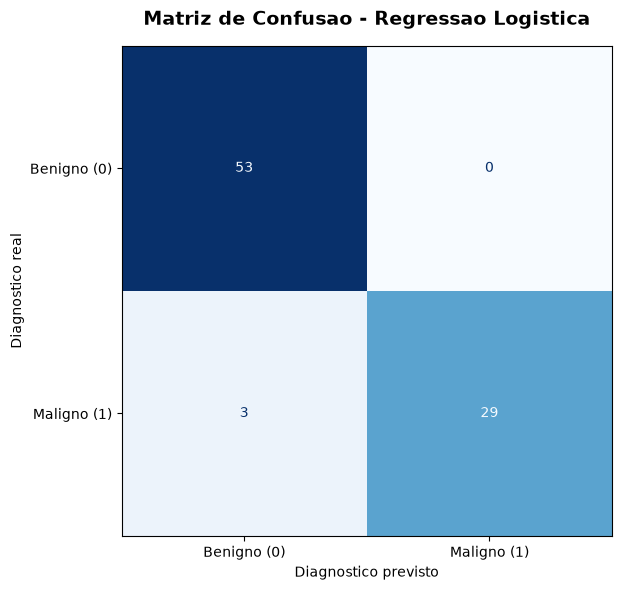


Grafico salvo em: c:\Users\Cliente\Projetos\tech-challenge-fase1\reports\figures\07_matriz_confusao_logistica_validacao.png
Matriz de confusao exportada com sucesso!


In [5]:

# ETAPA 5 - Grafico da matriz de confusao
# Regressao Logistica - Conjunto de validacao

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from pathlib import Path

print("=== GRAFICO DA MATRIZ DE CONFUSAO ===")

# 1. Criar a figura
fig, ax = plt.subplots(figsize=(8, 6))

# 2. Criar o objeto de visualizacao
visualizacao = ConfusionMatrixDisplay(
    confusion_matrix=matriz_confusao_logistica,
    display_labels=[
        "Benigno (0)",
        "Maligno (1)"
    ]
)

# 3. Construir o grafico
visualizacao.plot(
    ax=ax,
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

# 4. Configurar os titulos
ax.set_title(
    "Matriz de Confusao - Regressao Logistica",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Diagnostico previsto")
ax.set_ylabel("Diagnostico real")

# 5. Ajustar o layout
plt.tight_layout()

# 6. Localizar a pasta principal do projeto
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# 7. Preparar a pasta de figuras
pasta_figuras = raiz / "reports" / "figures"
pasta_figuras.mkdir(parents=True, exist_ok=True)

# 8. Salvar o grafico
arquivo = (
    pasta_figuras /
    "07_matriz_confusao_logistica_validacao.png"
)

fig.savefig(
    arquivo,
    dpi=300,
    bbox_inches="tight"
)

# 9. Mostrar o resultado
plt.show()

# 10. Confirmar que o arquivo foi salvo
assert arquivo.is_file()

print("\nGrafico salvo em:", arquivo)
print("Matriz de confusao exportada com sucesso!")


### Avaliação inicial da Regressão Logística — Matriz de Confusão

A Regressão Logística foi inicialmente avaliada utilizando 85 amostras do conjunto de validação, que não participaram do treinamento.

A matriz de confusão apresentou 53 verdadeiros negativos, 29 verdadeiros positivos, nenhum falso positivo e três falsos negativos.

O modelo realizou 82 classificações corretas, correspondentes a uma acurácia de aproximadamente 96,47%.

Entretanto, foram observadas três amostras malignas classificadas incorretamente como benignas, resultando em um recall de aproximadamente 90,63% para a classe maligna.

Embora os resultados iniciais indiquem bom desempenho neste conjunto de validação, a ocorrência de falsos negativos merece atenção especial devido à natureza do problema.

Nas próximas etapas, será realizada uma comparação com o algoritmo Random Forest, buscando investigar possíveis melhorias no reconhecimento das amostras malignas.

**Figura 7 — Matriz de confusão da Regressão Logística no conjunto de validação.**

Fonte: elaboração própria a partir do Breast Cancer Wisconsin Diagnostic.

In [6]:

# ETAPA 5 - Metricas de classificacao
# Regressao Logistica - Conjunto de validacao

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("=== METRICAS DA REGRESSAO LOGISTICA ===")

# 1. Calcular acuracia
acuracia = accuracy_score(
    y_val,
    previsoes_val
)

# 2. Calcular precisao da classe maligna
precisao = precision_score(
    y_val,
    previsoes_val,
    pos_label=1,
    zero_division=0
)

# 3. Calcular recall da classe maligna
sensibilidade = recall_score(
    y_val,
    previsoes_val,
    pos_label=1,
    zero_division=0
)

# 4. Calcular F1-Score da classe maligna
f1 = f1_score(
    y_val,
    previsoes_val,
    pos_label=1,
    zero_division=0
)

# 5. Exibir os resultados em porcentagem
print(f"\nAcuracia: {acuracia:.2%}")
print(f"Precisao: {precisao:.2%}")
print(f"Recall: {sensibilidade:.2%}")
print(f"F1-Score: {f1:.2%}")

# 6. Gerar relatorio completo
print("\n=== RELATORIO DE CLASSIFICACAO ===")

print(
    classification_report(
        y_val,
        previsoes_val,
        labels=[0, 1],
        target_names=["Benigno", "Maligno"],
        digits=4,
        zero_division=0
    )
)

# 7. Validar as metricas calculadas
assert abs(acuracia - 82/85) < 1e-10
assert abs(precisao - 1.0) < 1e-10
assert abs(sensibilidade - 29/32) < 1e-10
assert abs(f1 - 58/61) < 1e-10

print("Metricas validadas com sucesso!")


=== METRICAS DA REGRESSAO LOGISTICA ===

Acuracia: 96.47%
Precisao: 100.00%
Recall: 90.62%
F1-Score: 95.08%

=== RELATORIO DE CLASSIFICACAO ===
              precision    recall  f1-score   support

     Benigno     0.9464    1.0000    0.9725        53
     Maligno     1.0000    0.9062    0.9508        32

    accuracy                         0.9647        85
   macro avg     0.9732    0.9531    0.9616        85
weighted avg     0.9666    0.9647    0.9643        85

Metricas validadas com sucesso!


### Avaliação das métricas da Regressão Logística

A Regressão Logística foi avaliada utilizando 85 amostras do conjunto de validação, não utilizadas durante o treinamento.

O modelo apresentou acurácia de 96,47%, precisão de 100% para a classe maligna, sensibilidade de aproximadamente 90,63% e F1-Score de 95,08%.

Apesar do desempenho global elevado, foram identificados três falsos negativos, correspondentes a amostras malignas classificadas incorretamente como benignas.

Esse resultado demonstra a importância de utilizar diferentes métricas de avaliação, especialmente em problemas nos quais determinados tipos de erro apresentam maior relevância.

Nas próximas etapas, os resultados serão comparados com os obtidos pelo algoritmo Random Forest. A comparação considerará especialmente a sensibilidade da classe maligna, os falsos negativos e o equilíbrio geral entre as métricas.

Os resultados apresentados são referentes exclusivamente ao conjunto de validação e não constituem evidência de desempenho clínico.


## Treinamento do segundo modelo - Random Forest

Nesta etapa, sera utilizado o algoritmo Random Forest
como segunda abordagem de classificacao supervisionada.

O modelo sera configurado inicialmente com 200 arvores
de decisao e semente aleatoria 42.

O treinamento utilizara exclusivamente as 398 amostras
do conjunto de treinamento, preservando os conjuntos
de validacao e teste para suas respectivas finalidades.

O objetivo posterior sera comparar o desempenho deste
modelo com o da Regressao Logistica, especialmente
quanto aos falsos negativos da classe maligna.


In [7]:

# ETAPA 5 - Treinamento do Random Forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.utils.validation import check_is_fitted

print("=== TREINAMENTO DO RANDOM FOREST ===")

# 1. Criar o pipeline do Random Forest
pipeline_floresta = Pipeline(
    steps=[
        ("classificador", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# 2. Treinar somente com as 398 amostras
pipeline_floresta.fit(X_train, y_train)

# 3. Recuperar o classificador treinado
classificador_rf = pipeline_floresta.named_steps[
    "classificador"
]

# 4. Verificar se foi treinado
check_is_fitted(classificador_rf)

print("\nTreinamento concluido!")

# 5. Mostrar as informacoes do modelo
print(
    "Caracteristicas utilizadas:",
    classificador_rf.n_features_in_
)

print(
    "Classes reconhecidas:",
    classificador_rf.classes_
)

print(
    "Quantidade de arvores:",
    len(classificador_rf.estimators_)
)

# 6. Validar a estrutura do modelo
assert classificador_rf.n_features_in_ == 30

assert list(classificador_rf.classes_) == [0, 1]

assert len(classificador_rf.estimators_) == 200

print("\nRandom Forest treinado e validado com sucesso!")


=== TREINAMENTO DO RANDOM FOREST ===

Treinamento concluido!
Caracteristicas utilizadas: 30
Classes reconhecidas: [0 1]
Quantidade de arvores: 200

Random Forest treinado e validado com sucesso!


### Treinamento do modelo Random Forest

Como segunda abordagem de classificação supervisionada, foi selecionado o algoritmo Random Forest, baseado na combinação de múltiplas árvores de decisão.

A configuração inicial estabeleceu 200 árvores e semente aleatória 42, com o objetivo de assegurar a reprodutibilidade do experimento.

O treinamento foi planejado utilizando as mesmas 398 amostras e 30 características morfológicas empregadas no treinamento da Regressão Logística.

Diferentemente do primeiro modelo, o pipeline do Random Forest não inclui padronização, uma vez que algoritmos baseados em árvores de decisão geralmente não dependem da escala das variáveis.

Após o treinamento, o modelo será avaliado utilizando o mesmo conjunto de 85 amostras de validação, permitindo uma comparação entre as duas abordagens. A análise priorizará o recall da classe maligna, os falsos negativos e o equilíbrio entre as demais métricas de classificação.

## Primeiras previsões do Random Forest

Nesta etapa, o modelo Random Forest será utilizado
para realizar previsões nas 85 amostras de validação.

Serão obtidas as classes previstas e as probabilidades
estimadas de malignidade.

Os resultados serão utilizados posteriormente para
construir a matriz de confusão, calcular as métricas
de desempenho e comparar os dois classificadores.

In [8]:

# ETAPA 5 - Previsoes do Random Forest
# Utilizando as 85 amostras de validacao

import numpy as np
import pandas as pd

print("=== PREVISOES DO RANDOM FOREST ===")

# 1. Gerar as previsoes do modelo
previsoes_rf_val = pipeline_floresta.predict(
    X_val
)

# 2. Obter as probabilidades estimadas
probabilidades_rf_val = pipeline_floresta.predict_proba(
    X_val
)

# 3. Identificar a classe maligna (1)
classes_rf = pipeline_floresta.named_steps[
    "classificador"
].classes_

indice_maligno_rf = list(classes_rf).index(1)

# 4. Extrair a probabilidade de malignidade
probabilidades_maligno_rf = probabilidades_rf_val[
    :, indice_maligno_rf
]

# 5. Organizar os resultados em um DataFrame
resultados_rf_val = pd.DataFrame({
    "Diagnostico real": y_val.to_numpy(),
    "Diagnostico previsto": previsoes_rf_val,
    "Probabilidade maligno (%)": (
        probabilidades_maligno_rf * 100
    ).round(2)
}, index=X_val.index)

# 6. Exibir as primeiras dez previsoes
print("\nPrimeiras 10 previsoes do Random Forest:")

display(resultados_rf_val.head(10))

# 7. Mostrar a quantidade de previsoes
print("\nTotal de previsoes:")
print(len(previsoes_rf_val))

# 8. Mostrar a distribuicao das classes previstas
print("\nDistribuicao das classes previstas:")

print(
    pd.Series(previsoes_rf_val)
    .value_counts()
    .sort_index()
)

# 9. Validar os resultados
assert len(previsoes_rf_val) == 85

assert probabilidades_rf_val.shape == (85, 2)

assert np.allclose(
    probabilidades_rf_val.sum(axis=1),
    1
)

assert np.isin(
    previsoes_rf_val,
    [0, 1]
).all()

print("\nPrevisoes do Random Forest validadas!")


=== PREVISOES DO RANDOM FOREST ===

Primeiras 10 previsoes do Random Forest:


,Diagnostico real,Diagnostico previsto,Probabilidade maligno (%)
130,0,0,2.0
267,0,0,1.5
385,1,0,18.5
83,1,1,98.0
399,0,0,0.5
107,0,0,1.0
147,0,0,20.0
448,0,0,8.0
139,0,0,0.0
523,0,0,1.5



Total de previsoes:
85

Distribuicao das classes previstas:
0    56
1    29
Name: count, dtype: int64

Previsoes do Random Forest validadas!



## Matriz de confusão do Random Forest

Nesta etapa, será calculada a matriz de confusão
do Random Forest utilizando as mesmas 85 amostras
de validação empregadas na Regressão Logística.

O objetivo é identificar os acertos e erros
de classificação, especialmente os falsos negativos
da classe maligna.

Os resultados servirão de base para a comparação
posterior entre os dois algoritmos.


In [9]:

# ETAPA 5 - Matriz de confusao do Random Forest

from sklearn.metrics import confusion_matrix

print("=== MATRIZ DE CONFUSAO - RANDOM FOREST ===")

# 1. Calcular a matriz de confusao
# Usando os diagnosticos reais e as previsoes do RF

matriz_confusao_rf = confusion_matrix(
    y_val,
    previsoes_rf_val,
    labels=[0, 1]
)

# 2. Exibir a matriz
print("\nMatriz de confusao:")
print(matriz_confusao_rf)

# 3. Separar os quatro resultados
vn_rf, fp_rf, fn_rf, vp_rf = (
    matriz_confusao_rf.ravel()
)

# 4. Apresentar os resultados
print("\n=== INTERPRETACAO ===")

print("Verdadeiros negativos:", vn_rf)
print("Falsos positivos:", fp_rf)
print("Falsos negativos:", fn_rf)
print("Verdadeiros positivos:", vp_rf)

# 5. Verificar o total de amostras
total_rf = vn_rf + fp_rf + fn_rf + vp_rf

print("\nTotal de amostras avaliadas:", total_rf)

assert total_rf == 85

# 6. Confirmar a quantidade real de cada classe
assert vn_rf + fp_rf == 53
assert fn_rf + vp_rf == 32

# 7. Confirmar as quantidades previstas
assert vn_rf + fn_rf == 56
assert fp_rf + vp_rf == 29

print("\nMatriz de confusao do RF validada com sucesso!")


=== MATRIZ DE CONFUSAO - RANDOM FOREST ===

Matriz de confusao:
[[53  0]
 [ 3 29]]

=== INTERPRETACAO ===
Verdadeiros negativos: 53
Falsos positivos: 0
Falsos negativos: 3
Verdadeiros positivos: 29

Total de amostras avaliadas: 85

Matriz de confusao do RF validada com sucesso!



## Visualização da matriz de confusão do Random Forest

A matriz de confusão do Random Forest será
representada graficamente para facilitar a análise
das classificações realizadas no conjunto de validação.

O resultado será posteriormente comparado com a
matriz da Regressão Logística, considerando
principalmente os falsos negativos da classe maligna.


=== GRAFICO DA MATRIZ - RANDOM FOREST ===


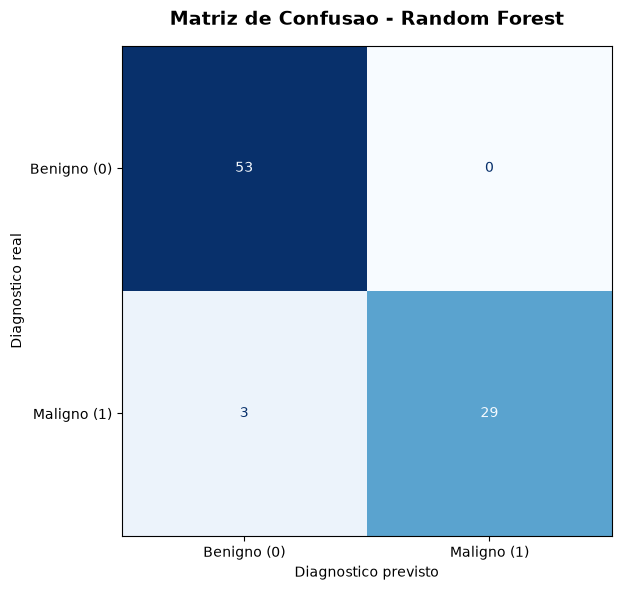


Grafico salvo em: c:\Users\Cliente\Projetos\tech-challenge-fase1\reports\figures\08_matriz_confusao_rf_validacao.png
Matriz do Random Forest exportada com sucesso!


In [10]:

# ETAPA 5 - Grafico da matriz de confusao
# Random Forest - Conjunto de validacao

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from pathlib import Path

print("=== GRAFICO DA MATRIZ - RANDOM FOREST ===")

# 1. Criar a figura
fig, ax = plt.subplots(figsize=(8, 6))

# 2. Preparar a matriz para visualizacao
visualizacao_rf = ConfusionMatrixDisplay(
    confusion_matrix=matriz_confusao_rf,
    display_labels=[
        "Benigno (0)",
        "Maligno (1)"
    ]
)

# 3. Construir o grafico
visualizacao_rf.plot(
    ax=ax,
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

# 4. Configurar o titulo e os eixos
ax.set_title(
    "Matriz de Confusao - Random Forest",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Diagnostico previsto")
ax.set_ylabel("Diagnostico real")

# 5. Ajustar o layout
plt.tight_layout()

# 6. Localizar a raiz do projeto
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# 7. Preparar a pasta de figuras
pasta_figuras = raiz / "reports" / "figures"

pasta_figuras.mkdir(
    parents=True,
    exist_ok=True
)

# 8. Definir o nome do arquivo
arquivo_rf = (
    pasta_figuras /
    "08_matriz_confusao_rf_validacao.png"
)

# 9. Salvar o grafico
fig.savefig(
    arquivo_rf,
    dpi=300,
    bbox_inches="tight"
)

# 10. Exibir o grafico
plt.show()

# 11. Confirmar que o arquivo existe
assert arquivo_rf.is_file()

print("\nGrafico salvo em:", arquivo_rf)
print("Matriz do Random Forest exportada com sucesso!")


## Avaliação das métricas do Random Forest

Nesta etapa, serão calculadas as métricas de
desempenho do Random Forest utilizando as 85
amostras do conjunto de validação.

Serão analisadas a acurácia, precisão, recall
e F1-score, considerando a classe maligna como
positiva.

O objetivo é comparar esses resultados com os
obtidos pela Regressão Logística, investigando
especialmente a ocorrência de falsos negativos.

In [11]:

# ETAPA 5 - Metricas do Random Forest
# Avaliacao com as 85 amostras de validacao

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

import numpy as np

print("=== METRICAS DO RANDOM FOREST ===")

# 1. Calcular a acuracia
acuracia_rf = accuracy_score(
    y_val,
    previsoes_rf_val
)

# 2. Calcular a precisao da classe maligna
precisao_rf = precision_score(
    y_val,
    previsoes_rf_val,
    pos_label=1,
    zero_division=0
)

# 3. Calcular o recall da classe maligna
recall_rf = recall_score(
    y_val,
    previsoes_rf_val,
    pos_label=1,
    zero_division=0
)

# 4. Calcular o F1-score
f1_rf = f1_score(
    y_val,
    previsoes_rf_val,
    pos_label=1,
    zero_division=0
)

# 5. Apresentar os resultados
print(f"\nAcuracia: {acuracia_rf:.2%}")
print(f"Precisao: {precisao_rf:.2%}")
print(f"Recall: {recall_rf:.2%}")
print(f"F1-Score: {f1_rf:.2%}")

# 6. Relatorio completo de classificacao
print("\n=== RELATORIO DE CLASSIFICACAO ===")

print(
    classification_report(
        y_val,
        previsoes_rf_val,
        labels=[0, 1],
        target_names=["Benigno", "Maligno"],
        digits=4,
        zero_division=0
    )
)

# 7. Conferir os valores com a matriz de confusao
assert np.isclose(acuracia_rf, 82 / 85)
assert np.isclose(precisao_rf, 1.0)
assert np.isclose(recall_rf, 29 / 32)
assert np.isclose(f1_rf, 58 / 61)

print("\nMetricas do Random Forest validadas!")


=== METRICAS DO RANDOM FOREST ===

Acuracia: 96.47%
Precisao: 100.00%
Recall: 90.62%
F1-Score: 95.08%

=== RELATORIO DE CLASSIFICACAO ===
              precision    recall  f1-score   support

     Benigno     0.9464    1.0000    0.9725        53
     Maligno     1.0000    0.9062    0.9508        32

    accuracy                         0.9647        85
   macro avg     0.9732    0.9531    0.9616        85
weighted avg     0.9666    0.9647    0.9643        85


Metricas do Random Forest validadas!


### Avaliação inicial do Random Forest

O modelo Random Forest foi avaliado utilizando as mesmas 85 amostras do conjunto de validação empregadas na avaliação da Regressão Logística.

A matriz de confusão apresentou 53 verdadeiros negativos, 29 verdadeiros positivos, nenhum falso positivo e três falsos negativos.

Esses resultados correspondem a uma acurácia de 96,47%, precisão de 100% para a classe maligna, recall de aproximadamente 90,63% e F1-score de 95,08%.

Observou-se que ambos os algoritmos apresentaram matrizes de confusão idênticas. Entretanto, uma comparação preliminar das previsões individuais identificou diferenças entre suas classificações.

Dessa forma, a análise será ampliada para investigar os registros classificados incorretamente por cada modelo, antes de definir a abordagem mais adequada para as próximas etapas.

Os resultados correspondem ao conjunto de validação e não representam uma validação clínica do sistema.


## Análise individual dos erros de classificação

Nesta etapa, serão comparadas individualmente as
previsões da Regressão Logística e do Random Forest.

A análise utilizará as 85 amostras do conjunto
de validação.

O objetivo é identificar os registros classificados
incorretamente por cada algoritmo, verificar os
erros compartilhados e investigar divergências
entre as previsões.

Serão analisadas também as probabilidades estimadas
de malignidade, sem interpretá-las como riscos
clínicos validados.

O conjunto de teste permanecerá reservado.


In [12]:

# ETAPA 5 - Comparacao individual dos erros
# Regressao Logistica x Random Forest

import pandas as pd

print("=== ANALISE INDIVIDUAL DOS ERROS ===")

# 1. Reunir os resultados dos dois modelos
comparacao_individual = pd.DataFrame({

    "Diagnostico real": y_val.to_numpy(),

    "Previsao Logistica": previsoes_val,

    "Previsao Random Forest": previsoes_rf_val,

    "Prob. Logistica (%)": (
        probabilidades_maligno * 100
    ).round(2),

    "Prob. Random Forest (%)": (
        probabilidades_maligno_rf * 100
    ).round(2)

}, index=X_val.index)

# 2. Identificar os erros da Regressao Logistica
erros_logistica = comparacao_individual[
    comparacao_individual["Diagnostico real"] !=
    comparacao_individual["Previsao Logistica"]
]

# 3. Identificar os erros do Random Forest
erros_floresta = comparacao_individual[
    comparacao_individual["Diagnostico real"] !=
    comparacao_individual["Previsao Random Forest"]
]

# 4. Identificar as divergencias entre os modelos
divergencias = comparacao_individual[
    comparacao_individual["Previsao Logistica"] !=
    comparacao_individual["Previsao Random Forest"]
]

# 5. Identificar indices com erros compartilhados
indices_comuns = (
    set(erros_logistica.index) &
    set(erros_floresta.index)
)

# 6. Exibir os resultados
print("\n=== ERROS DA REGRESSAO LOGISTICA ===")
display(erros_logistica)

print("\n=== ERROS DO RANDOM FOREST ===")
display(erros_floresta)

print("\n=== PREVISOES DIVERGENTES ===")
display(divergencias)

# 7. Apresentar um resumo
print("\n=== RESUMO ===")

print("Erros da Logistica:", len(erros_logistica))
print("Erros do Random Forest:", len(erros_floresta))

print("Erros compartilhados:", len(indices_comuns))
print("Previsoes divergentes:", len(divergencias))

print("Indices dos erros compartilhados:")
print(sorted(indices_comuns))

# 8. Validacoes
assert len(comparacao_individual) == 85
assert len(erros_logistica) == 3
assert len(erros_floresta) == 3
assert len(divergencias) >= 2

print("\nAnalise individual concluida com sucesso!")


=== ANALISE INDIVIDUAL DOS ERROS ===

=== ERROS DA REGRESSAO LOGISTICA ===


,Diagnostico real,Previsao Logistica,Previsao Random Forest,Prob. Logistica (%),Prob. Random Forest (%)
73,1,0,0,5.91,16.5
215,1,0,1,37.29,53.5
190,1,0,1,24.27,76.5



=== ERROS DO RANDOM FOREST ===


,Diagnostico real,Previsao Logistica,Previsao Random Forest,Prob. Logistica (%),Prob. Random Forest (%)
385,1,1,0,84.50,18.5
193,1,1,0,96.50,46.0
73,1,0,0,5.91,16.5



=== PREVISOES DIVERGENTES ===


,Diagnostico real,Previsao Logistica,Previsao Random Forest,Prob. Logistica (%),Prob. Random Forest (%)
385,1,1,0,84.50,18.5
193,1,1,0,96.50,46.0
215,1,0,1,37.29,53.5
190,1,0,1,24.27,76.5



=== RESUMO ===
Erros da Logistica: 3
Erros do Random Forest: 3
Erros compartilhados: 1
Previsoes divergentes: 4
Indices dos erros compartilhados:
[73]

Analise individual concluida com sucesso!



## Comparação visual das probabilidades dos modelos

Nesta etapa, serão comparadas as probabilidades
estimadas de malignidade nas amostras classificadas
incorretamente por pelo menos um dos algoritmos.

O gráfico permitirá visualizar as divergências
entre a Regressão Logística e o Random Forest,
considerando o limiar de classificação de 50%.

O objetivo é investigar a complementaridade dos
modelos e fundamentar futuras estratégias de melhoria.


=== COMPARACAO VISUAL DOS MODELOS ===
Total de amostras analisadas: 5


,Diagnostico real,Previsao Logistica,Previsao Random Forest,Prob. Logistica (%),Prob. Random Forest (%)
73,1,0,0,5.91,16.5
190,1,0,1,24.27,76.5
193,1,1,0,96.50,46.0
215,1,0,1,37.29,53.5
385,1,1,0,84.50,18.5


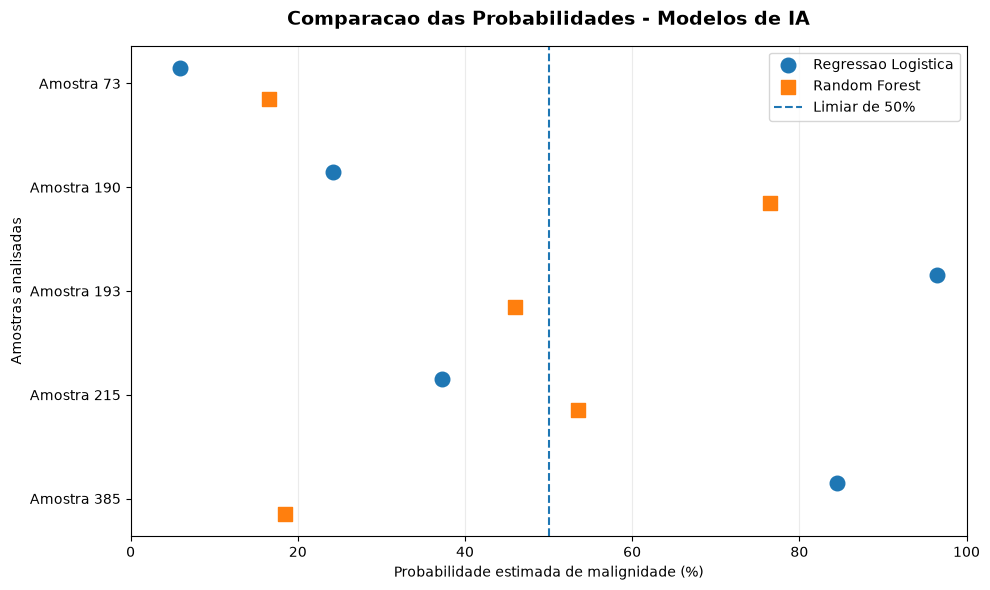


Grafico salvo em: c:\Users\Cliente\Projetos\tech-challenge-fase1\reports\figures\09_comparacao_probabilidades_modelos.png
Comparacao visual concluida com sucesso!


In [13]:

# ETAPA 5 - Comparacao visual dos erros
# Regressao Logistica x Random Forest

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("=== COMPARACAO VISUAL DOS MODELOS ===")

# 1. Reunir os indices de todos os erros
indices_erros = sorted(
    set(erros_logistica.index) |
    set(erros_floresta.index)
)

# 2. Selecionar apenas as amostras problematicas
dados_grafico = comparacao_individual.loc[
    indices_erros
].copy()

print("Total de amostras analisadas:", len(dados_grafico))

display(dados_grafico)

# 3. Criar as posicoes das amostras no grafico
posicoes = np.arange(len(dados_grafico))

fig, ax = plt.subplots(figsize=(10, 6))

# 4. Probabilidades da Regressao Logistica
ax.scatter(
    dados_grafico["Prob. Logistica (%)"],
    posicoes - 0.15,
    s=110,
    marker="o",
    label="Regressao Logistica"
)

# 5. Probabilidades do Random Forest
ax.scatter(
    dados_grafico["Prob. Random Forest (%)"],
    posicoes + 0.15,
    s=110,
    marker="s",
    label="Random Forest"
)

# 6. Marcar o limiar de classificacao
ax.axvline(
    x=50,
    linestyle="--",
    linewidth=1.5,
    label="Limiar de 50%"
)

# 7. Configurar os eixos
ax.set_yticks(posicoes)

ax.set_yticklabels([
    f"Amostra {indice}"
    for indice in indices_erros
])

ax.invert_yaxis()

ax.set_xlim(0, 100)

ax.set_xlabel(
    "Probabilidade estimada de malignidade (%)"
)

ax.set_ylabel("Amostras analisadas")

ax.set_title(
    "Comparacao das Probabilidades - Modelos de IA",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.grid(axis="x", alpha=0.25)
ax.legend()

plt.tight_layout()

# 8. Localizar a pasta de figuras
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

pasta_figuras = raiz / "reports" / "figures"
pasta_figuras.mkdir(parents=True, exist_ok=True)

# 9. Salvar o grafico
arquivo = (
    pasta_figuras /
    "09_comparacao_probabilidades_modelos.png"
)

fig.savefig(
    arquivo,
    dpi=300,
    bbox_inches="tight"
)

# 10. Exibir o grafico
plt.show()

# 11. Confirmar o arquivo
assert arquivo.is_file()

print("\nGrafico salvo em:", arquivo)
print("Comparacao visual concluida com sucesso!")


### Análise comparativa dos erros individuais

Após a avaliação das métricas de desempenho, foi realizada uma análise individual das classificações incorretas produzidas pela Regressão Logística e pelo Random Forest no conjunto de validação.

Ambos os classificadores apresentaram três falsos negativos. Entretanto, identificou-se que os erros ocorreram em registros diferentes.

A Regressão Logística classificou incorretamente as amostras de índices 73, 190 e 215, enquanto o Random Forest apresentou erros nas amostras 73, 193 e 385.

Apenas a amostra 73 foi classificada incorretamente pelos dois algoritmos. Foram identificadas quatro amostras com previsões divergentes.

Esses resultados evidenciam que modelos com métricas agregadas idênticas podem apresentar comportamentos distintos diante de registros específicos.

A análise sugere uma possível complementaridade entre os classificadores, justificando a investigação posterior de estratégias de combinação e ajustes dos limiares de decisão.

Entretanto, qualquer melhoria observada no conjunto de validação deverá ser interpretada como exploratória, sendo necessária avaliação independente para estimar sua capacidade de generalização.


## Análise exploratória dos limiares de classificação

Nesta etapa, serão investigados diferentes limiares
de classificação para a Regressão Logística e o
Random Forest.

Serão considerados os limiares de 10%, 20%, 30%,
40% e 50%.

O objetivo é observar como a alteração do limiar
influencia a quantidade de falsos positivos, falsos
negativos, acurácia, precisão, recall e F1-score.

Os modelos já treinados não serão modificados.

Esta análise é exploratória e utiliza exclusivamente
o conjunto de validação. O conjunto de teste
permanecerá reservado para a avaliação final.


In [14]:

# ETAPA 5 - Analise dos limiares de classificacao
# Regressao Logistica x Random Forest

import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=== ANALISE DOS LIMIARES ===")

# 1. Definir os limiares que serao investigados
limiares = [0.10, 0.20, 0.30, 0.40, 0.50]

# 2. Reunir as probabilidades dos dois modelos
# Utilizamos os valores originais, sem arredondamento
probabilidades_modelos = {
    "Regressao Logistica": probabilidades_maligno,
    "Random Forest": probabilidades_maligno_rf
}

# 3. Criar uma lista para armazenar os resultados
resultados_limiares = []

# 4. Percorrer cada modelo
for nome_modelo, probabilidades in probabilidades_modelos.items():

    # Percorrer cada limiar de classificacao
    for limiar in limiares:

        # 5. Gerar as classificacoes com o novo limiar
        # Empates ficam na classe 0
        previsoes_limiar = (
            probabilidades > limiar
        ).astype(int)

        # 6. Calcular a matriz de confusao
        matriz = confusion_matrix(
            y_val,
            previsoes_limiar,
            labels=[0, 1]
        )

        vn, fp, fn, vp = matriz.ravel()

        # 7. Calcular as metricas
        acuracia_limiar = accuracy_score(
            y_val, previsoes_limiar
        )

        precisao_limiar = precision_score(
            y_val, previsoes_limiar,
            pos_label=1,
            zero_division=0
        )

        recall_limiar = recall_score(
            y_val, previsoes_limiar,
            pos_label=1,
            zero_division=0
        )

        f1_limiar = f1_score(
            y_val, previsoes_limiar,
            pos_label=1,
            zero_division=0
        )

        # 8. Armazenar os resultados
        resultados_limiares.append({
            "Modelo": nome_modelo,
            "Limiar (%)": int(limiar * 100),
            "VN": int(vn),
            "FP": int(fp),
            "FN": int(fn),
            "VP": int(vp),
            "Acuracia (%)": round(acuracia_limiar * 100, 2),
            "Precisao (%)": round(precisao_limiar * 100, 2),
            "Recall (%)": round(recall_limiar * 100, 2),
            "F1 (%)": round(f1_limiar * 100, 2)
        })

# 9. Transformar os resultados em DataFrame
tabela_limiares = pd.DataFrame(
    resultados_limiares
)

# 10. Exibir a tabela comparativa
print("\n=== RESULTADOS POR MODELO E LIMIAR ===")

display(tabela_limiares)

# 11. Validacoes
assert len(tabela_limiares) == 10

assert (
    tabela_limiares[["VN", "FP", "FN", "VP"]]
    .sum(axis=1) == 85
).all()

# 12. Conferir o limiar original de 50%
referencia = tabela_limiares[
    tabela_limiares["Limiar (%)"] == 50
]

assert (referencia["FN"] == 3).all()
assert (referencia["FP"] == 0).all()

print("\nAnalise dos limiares concluida com sucesso!")


=== ANALISE DOS LIMIARES ===

=== RESULTADOS POR MODELO E LIMIAR ===


,Modelo,Limiar (%),VN,FP,FN,VP,Acuracia (%),Precisao (%),Recall (%),F1 (%)
0,Regressao Logistica,10,50,3,1,31,95.29,91.18,96.88,93.94
1,Regressao Logistica,20,52,1,1,31,97.65,96.88,96.88,96.88
2,Regressao Logistica,30,53,0,2,30,97.65,100.00,93.75,96.77
3,Regressao Logistica,40,53,0,3,29,96.47,100.00,90.62,95.08
4,Regressao Logistica,50,53,0,3,29,96.47,100.00,90.62,95.08
5,Random Forest,10,43,10,0,32,88.24,76.19,100.00,86.49
6,Random Forest,20,48,5,2,30,91.76,85.71,93.75,89.55
7,Random Forest,30,50,3,2,30,94.12,90.91,93.75,92.31
8,Random Forest,40,52,1,2,30,96.47,96.77,93.75,95.24
9,Random Forest,50,53,0,3,29,96.47,100.00,90.62,95.08



Analise dos limiares concluida com sucesso!



## Análise exploratória da combinação dos modelos

Nesta etapa, será investigada a combinação das
previsões da Regressão Logística e do Random Forest
utilizando o operador lógico OU (OR).

A classificação combinada será maligna quando
pelo menos um dos classificadores identificar
a amostra como maligna.

Serão utilizadas as previsões existentes no
conjunto de validação com limiar padrão de 50%.

Esta análise é exploratória e não representa
uma validação independente da estratégia.

O conjunto de teste permanecerá reservado.


In [15]:

# ETAPA 5 - Combinacao exploratoria dos modelos
# Estrategia OU (OR) com limiar de 50%

import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=== COMBINACAO DOS MODELOS - OPERADOR OU ===")

# 1. Combinar as previsoes existentes
# Se algum modelo prever maligno (1),
# a combinacao tambem preve maligno.

previsoes_combinadas = np.logical_or(
    previsoes_val == 1,
    previsoes_rf_val == 1
).astype(int)

# 2. Calcular a matriz de confusao
matriz_combinada = confusion_matrix(
    y_val,
    previsoes_combinadas,
    labels=[0, 1]
)

vn_comb, fp_comb, fn_comb, vp_comb = (
    matriz_combinada.ravel()
)

# 3. Exibir a matriz
print("\nMatriz de confusao:")
print(matriz_combinada)

print("\nVerdadeiros negativos:", vn_comb)
print("Falsos positivos:", fp_comb)
print("Falsos negativos:", fn_comb)
print("Verdadeiros positivos:", vp_comb)

# 4. Calcular as metricas
acuracia_comb = accuracy_score(
    y_val, previsoes_combinadas
)

precisao_comb = precision_score(
    y_val, previsoes_combinadas,
    pos_label=1, zero_division=0
)

recall_comb = recall_score(
    y_val, previsoes_combinadas,
    pos_label=1, zero_division=0
)

f1_comb = f1_score(
    y_val, previsoes_combinadas,
    pos_label=1, zero_division=0
)

# 5. Exibir as metricas
print("\n=== METRICAS DA COMBINACAO ===")

print(f"Acuracia: {acuracia_comb:.2%}")
print(f"Precisao: {precisao_comb:.2%}")
print(f"Recall: {recall_comb:.2%}")
print(f"F1-Score: {f1_comb:.2%}")

# 6. Verificar os resultados
assert len(previsoes_combinadas) == 85
assert matriz_combinada.sum() == 85

# 7. Mostrar registros ainda classificados
# incorretamente
resultado_combinado = pd.DataFrame({
    "Diagnostico real": y_val.to_numpy(),
    "Previsao combinada": previsoes_combinadas
}, index=X_val.index)

erros_combinacao = resultado_combinado[
    resultado_combinado["Diagnostico real"] !=
    resultado_combinado["Previsao combinada"]
]

print("\n=== ERROS DA COMBINACAO ===")
display(erros_combinacao)

print("\nAnalise exploratoria concluida!")


=== COMBINACAO DOS MODELOS - OPERADOR OU ===

Matriz de confusao:
[[53  0]
 [ 1 31]]

Verdadeiros negativos: 53
Falsos positivos: 0
Falsos negativos: 1
Verdadeiros positivos: 31

=== METRICAS DA COMBINACAO ===
Acuracia: 98.82%
Precisao: 100.00%
Recall: 96.88%
F1-Score: 98.41%

=== ERROS DA COMBINACAO ===


,Diagnostico real,Previsao combinada
73,1,0



Analise exploratoria concluida!



## Validação cruzada estratificada dos classificadores

Nesta etapa, será realizada uma validação cruzada
estratificada com cinco divisões (5-Fold).

Serão utilizados exclusivamente os 398 registros
do conjunto original de treinamento.

Serão investigadas três estratégias:
- Regressão Logística com limiar de 50%.
- Random Forest com limiar de 50%.
- Combinação OR dos dois modelos.

As previsões serão geradas fora das respectivas
partições de treinamento, evitando que uma amostra
seja avaliada por um modelo treinado com ela.

Os conjuntos de validação e teste originais
permanecerão fora desta análise.

Os resultados serão interpretados como evidências
exploratórias de robustez, não como avaliação
independente definitiva.


In [16]:

# ETAPA 5 - Validacao cruzada estratificada
# Comparacao entre os dois modelos e a combinacao OR

import numpy as np
import pandas as pd

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict
)

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=== VALIDACAO CRUZADA - 5 FOLDS ===")

# 1. Configurar as cinco divisoes
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 2. Gerar probabilidades fora das amostras
# utilizadas em cada treinamento

print("\nAvaliando a Regressao Logistica...")

prob_cv_log = cross_val_predict(
    pipeline_logistica,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

print("Avaliando o Random Forest...")

prob_cv_rf = cross_val_predict(
    pipeline_floresta,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

# 3. Aplicar o limiar de 50%
pred_cv_log = (prob_cv_log > 0.50).astype(int)
pred_cv_rf = (prob_cv_rf > 0.50).astype(int)

# 4. Combinar as previsoes com o operador OU
pred_cv_or = np.logical_or(
    pred_cv_log == 1,
    pred_cv_rf == 1
).astype(int)

# 5. Organizar as estrategias
estrategias_cv = {
    "Regressao Logistica": pred_cv_log,
    "Random Forest": pred_cv_rf,
    "Combinacao OR": pred_cv_or
}

# 6. Calcular os indicadores
resultados_cv = []

for nome, previsoes in estrategias_cv.items():

    matriz = confusion_matrix(
        y_train,
        previsoes,
        labels=[0, 1]
    )

    vn, fp, fn, vp = matriz.ravel()

    resultados_cv.append({
        "Modelo": nome,
        "VN": int(vn),
        "FP": int(fp),
        "FN": int(fn),
        "VP": int(vp),
        "Acuracia (%)": round(
            accuracy_score(y_train, previsoes) * 100, 2
        ),
        "Precisao (%)": round(
            precision_score(
                y_train, previsoes,
                pos_label=1,
                zero_division=0
            ) * 100, 2
        ),
        "Recall (%)": round(
            recall_score(
                y_train, previsoes,
                pos_label=1,
                zero_division=0
            ) * 100, 2
        ),
        "F1 (%)": round(
            f1_score(
                y_train, previsoes,
                pos_label=1,
                zero_division=0
            ) * 100, 2
        )
    })

# 7. Criar a tabela comparativa
tabela_cv = pd.DataFrame(resultados_cv)

print("\n=== RESULTADOS AGREGADOS OUT-OF-FOLD ===")

display(tabela_cv)

# 8. Verificar a integridade dos resultados
assert len(tabela_cv) == 3

assert all(
    len(previsoes) == len(y_train) == 398
    for previsoes in estrategias_cv.values()
)

assert (
    tabela_cv[["VN", "FP", "FN", "VP"]]
    .sum(axis=1) == 398
).all()

print("\nValidacao cruzada executada com sucesso!")


=== VALIDACAO CRUZADA - 5 FOLDS ===

Avaliando a Regressao Logistica...
Avaliando o Random Forest...

=== RESULTADOS AGREGADOS OUT-OF-FOLD ===


,Modelo,VN,FP,FN,VP,Acuracia (%),Precisao (%),Recall (%),F1 (%)
0,Regressao Logistica,250,0,7,141,98.24,100.00,95.27,97.58
1,Random Forest,241,9,12,136,94.72,93.79,91.89,92.83
2,Combinacao OR,241,9,5,143,96.48,94.08,96.62,95.33



Validacao cruzada executada com sucesso!



## Analise do desempenho em cada fold

Nesta etapa, serao examinados separadamente os
resultados dos cinco folds da validacao cruzada.

O objetivo e verificar a variacao do desempenho
da Regressao Logistica, Random Forest e combinacao OR.

Serao observados especialmente os falsos negativos,
falsos positivos, recall e F1-score de cada fold.

As previsoes out-of-fold ja calculadas serao
reutilizadas, sem necessidade de novo treinamento.

O conjunto de teste permanecera reservado.


In [17]:

# ETAPA 5 - Avaliacao individual dos cinco folds

import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=== ANALISE INDIVIDUAL DOS 5 FOLDS ===")

# 1. Preparar os diagnosticos reais
y_cv = np.asarray(y_train)

# 2. Recuperar as previsoes OOF existentes
modelos_cv = {
    "Regressao Logistica": np.asarray(pred_cv_log),
    "Random Forest": np.asarray(pred_cv_rf),
    "Combinacao OR": np.asarray(pred_cv_or)
}

# 3. Criar lista para armazenar as metricas
resultados_por_fold = []
indices_avaliados = []

# 4. Percorrer as mesmas cinco divisoes
for numero_fold, (_, indices_val) in enumerate(
    cv.split(X_train, y_train),
    start=1
):

    indices_avaliados.extend(indices_val.tolist())

    # Diagnosticos reais do fold
    reais = y_cv[indices_val]

    # 5. Avaliar cada estrategia
    for nome, previsoes in modelos_cv.items():

        previstos = previsoes[indices_val]

        matriz = confusion_matrix(
            reais,
            previstos,
            labels=[0, 1]
        )

        vn, fp, fn, vp = matriz.ravel()

        resultados_por_fold.append({
            "Fold": numero_fold,
            "Modelo": nome,
            "Amostras": len(reais),
            "FP": int(fp),
            "FN": int(fn),
            "Acuracia (%)": accuracy_score(
                reais, previstos
            ) * 100,
            "Precisao (%)": precision_score(
                reais, previstos,
                pos_label=1,
                zero_division=0
            ) * 100,
            "Recall (%)": recall_score(
                reais, previstos,
                pos_label=1,
                zero_division=0
            ) * 100,
            "F1 (%)": f1_score(
                reais, previstos,
                pos_label=1,
                zero_division=0
            ) * 100
        })

# 6. Organizar os resultados
tabela_por_fold = pd.DataFrame(
    resultados_por_fold
)

print("\n=== RESULTADOS DE CADA FOLD ===")
display(tabela_por_fold.round(2))

# 7. Comparar o recall de cada fold
print("\n=== RECALL POR FOLD ===")

display(
    tabela_por_fold.pivot(
        index="Fold",
        columns="Modelo",
        values="Recall (%)"
    ).round(2)
)

# 8. Comparar os falsos negativos
print("\n=== FALSOS NEGATIVOS POR FOLD ===")

display(
    tabela_por_fold.pivot(
        index="Fold",
        columns="Modelo",
        values="FN"
    )
)

# 9. Resumir as metricas por modelo
resumo_folds = (
    tabela_por_fold
    .groupby("Modelo", as_index=False)
    .agg(
        recall_medio=("Recall (%)", "mean"),
        recall_desvio=("Recall (%)", "std"),
        f1_medio=("F1 (%)", "mean"),
        fn_total=("FN", "sum"),
        fp_total=("FP", "sum")
    )
)

print("\n=== RESUMO DOS CINCO FOLDS ===")
display(resumo_folds.round(2))

# 10. Validar a integridade
assert len(tabela_por_fold) == 15

assert len(indices_avaliados) == 398
assert len(set(indices_avaliados)) == 398

for nome, previsoes in modelos_cv.items():

    matriz_total = confusion_matrix(
        y_cv, previsoes, labels=[0, 1]
    )

    linhas = tabela_por_fold[
        tabela_por_fold["Modelo"] == nome
    ]

    # Somar VN, FP, FN e VP dos cinco folds
    # e conferir com a matriz agregada
    totais = [
        int((linhas["Amostras"]
             - linhas["FP"]
             - linhas["FN"]
             - 0).sum())
    ] if False else None

    assert linhas["FP"].sum() == matriz_total[0, 1]
    assert linhas["FN"].sum() == matriz_total[1, 0]

print("\nAnalise dos folds concluida com sucesso!")


=== ANALISE INDIVIDUAL DOS 5 FOLDS ===

=== RESULTADOS DE CADA FOLD ===


,Fold,Modelo,Amostras,FP,FN,Acuracia (%),Precisao (%),Recall (%),F1 (%)
0,1,Regressao Logistica,80,0,2,97.50,100.00,93.33,96.55
1,1,Random Forest,80,5,1,92.50,85.29,96.67,90.62
2,1,Combinacao OR,80,5,1,92.50,85.29,96.67,90.62
3,2,Regressao Logistica,80,0,1,98.75,100.00,96.67,98.31
4,2,Random Forest,80,0,2,97.50,100.00,93.33,96.55
5,2,Combinacao OR,80,0,1,98.75,100.00,96.67,98.31
6,3,Regressao Logistica,80,0,1,98.75,100.00,96.67,98.31
7,3,Random Forest,80,1,1,97.50,96.67,96.67,96.67
8,3,Combinacao OR,80,1,1,97.50,96.67,96.67,96.67
9,4,Regressao Logistica,79,0,1,98.73,100.00,96.55,98.25



=== RECALL POR FOLD ===


Modelo,Combinacao OR,Random Forest,Regressao Logistica
Fold,,,
1,96.67,96.67,93.33
2,96.67,93.33,96.67
3,96.67,96.67,96.67
4,96.55,82.76,96.55
5,96.55,89.66,93.10



=== FALSOS NEGATIVOS POR FOLD ===


Modelo,Combinacao OR,Random Forest,Regressao Logistica
Fold,,,
1,1,1,2
2,1,2,1
3,1,1,1
4,1,5,1
5,1,3,2



=== RESUMO DOS CINCO FOLDS ===


,Modelo,recall_medio,recall_desvio,f1_medio,fn_total,fp_total
0,Combinacao OR,96.62,0.06,95.44,5,9
1,Random Forest,91.82,5.83,92.82,12,9
2,Regressao Logistica,95.26,1.87,97.57,7,0



Analise dos folds concluida com sucesso!



## Comparacao exploratoria das estrategias candidatas

Nesta etapa, serao comparadas cinco configuracoes
utilizando as previsoes out-of-fold ja calculadas.

Serao analisados:
- Regressao Logistica com limiar de 50%
- Regressao Logistica com limiar de 20%
- Random Forest com limiar de 50%
- Random Forest com limiar de 10%
- Combinacao OR com limiar de 50%

O objetivo e investigar o equilibrio entre
falsos negativos, falsos positivos, sensibilidade
e demais metricas de classificacao.

Os resultados serao utilizados para orientar
a selecao metodologica, sem acessar o conjunto
de teste reservado.


In [18]:

# ETAPA 5 - Comparacao de estrategias candidatas
# Utilizando as previsoes out-of-fold existentes

import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=== COMPARACAO DAS ESTRATEGIAS ===")

# 1. Recuperar os diagnosticos reais
y_real_cv = np.asarray(y_train)

# 2. Definir as estrategias candidatas
# Nenhum modelo sera treinado novamente

candidatos = {
    "Logistica - 50%": np.asarray(pred_cv_log),

    "Logistica - 20%": (
        np.asarray(prob_cv_log) > 0.20
    ).astype(int),

    "Random Forest - 50%": np.asarray(pred_cv_rf),

    "Random Forest - 10%": (
        np.asarray(prob_cv_rf) > 0.10
    ).astype(int),

    "Combinacao OR - 50%": np.asarray(pred_cv_or)
}

# 3. Calcular as metricas
resultados_candidatos = []

for nome, previstos in candidatos.items():

    matriz = confusion_matrix(
        y_real_cv,
        previstos,
        labels=[0, 1]
    )

    vn, fp, fn, vp = matriz.ravel()

    resultados_candidatos.append({
        "Estrategia": nome,
        "VN": int(vn),
        "FP": int(fp),
        "FN": int(fn),
        "VP": int(vp),

        "Acuracia (%)": round(
            accuracy_score(y_real_cv, previstos) * 100,
            2
        ),

        "Precisao (%)": round(
            precision_score(
                y_real_cv, previstos,
                zero_division=0
            ) * 100,
            2
        ),

        "Recall (%)": round(
            recall_score(
                y_real_cv, previstos
            ) * 100,
            2
        ),

        "F1 (%)": round(
            f1_score(
                y_real_cv, previstos
            ) * 100,
            2
        ),

        "Taxa FP (%)": round(
            100 * fp / (vn + fp),
            2
        )
    })

# 4. Organizar os resultados
tabela_candidatos = pd.DataFrame(
    resultados_candidatos
)

print("\n=== TABELA COMPARATIVA ===")
display(tabela_candidatos)

# 5. Validar os resultados
assert len(tabela_candidatos) == 5

assert (
    tabela_candidatos[["VN", "FP", "FN", "VP"]]
    .sum(axis=1) == 398
).all()

# Conferir as configuracoes ja avaliadas
logistica_base = tabela_candidatos.iloc[0]
floresta_base = tabela_candidatos.iloc[2]
combinacao_base = tabela_candidatos.iloc[4]

assert logistica_base["FN"] == 7
assert logistica_base["FP"] == 0

assert floresta_base["FN"] == 12
assert floresta_base["FP"] == 9

assert combinacao_base["FN"] == 5
assert combinacao_base["FP"] == 9

print("\nComparacao exploratoria validada!")


=== COMPARACAO DAS ESTRATEGIAS ===

=== TABELA COMPARATIVA ===


,Estrategia,VN,FP,FN,VP,Acuracia (%),Precisao (%),Recall (%),F1 (%),Taxa FP (%)
0,Logistica - 50%,250,0,7,141,98.24,100.00,95.27,97.58,0.0
1,Logistica - 20%,237,13,4,144,95.73,91.72,97.30,94.43,5.2
2,Random Forest - 50%,241,9,12,136,94.72,93.79,91.89,92.83,3.6
3,Random Forest - 10%,201,49,4,144,86.68,74.61,97.30,84.46,19.6
4,Combinacao OR - 50%,241,9,5,143,96.48,94.08,96.62,95.33,3.6



Comparacao exploratoria validada!



## Analise de sensibilidade aos custos dos erros

Nesta etapa, sera realizada uma simulacao exploratoria
de diferentes pesos relativos para falsos negativos
e falsos positivos.

O objetivo e verificar como a escolha da estrategia
pode mudar quando consideramos diferentes prioridades.

Os pesos utilizados sao hipoteticos e nao
representam custos clinicos validados.

Esta analise reutiliza as metricas out-of-fold
anteriormente calculadas e nao utiliza o
conjunto de teste reservado.


In [19]:

# ETAPA 5 - Analise de sensibilidade ao custo dos erros

import pandas as pd

print("=== ANALISE DE CUSTOS HIPOTETICOS ===")

# 1. Definir pesos hipoteticos para falsos negativos
pesos_fn = [1, 2, 3, 4, 5, 10]

# 2. Armazenar os resultados
resultados_custos = []

# 3. Percorrer cada peso
for peso in pesos_fn:

    # Avaliar cada estrategia
    for _, linha in tabela_candidatos.iterrows():

        # Calcular o custo hipotetico
        custo = (
            linha["FP"] * 1 +
            linha["FN"] * peso
        )

        resultados_custos.append({
            "Peso FN": peso,
            "Estrategia": linha["Estrategia"],
            "Custo": int(custo)
        })

# 4. Criar o DataFrame
tabela_custos = pd.DataFrame(resultados_custos)

# 5. Organizar a comparacao
comparacao_custos = tabela_custos.pivot(
    index="Peso FN",
    columns="Estrategia",
    values="Custo"
)

print("\n=== CUSTOS POR ESTRATEGIA ===")
display(comparacao_custos)

# 6. Identificar o menor custo em cada cenario
indices_menor_custo = (
    tabela_custos.groupby("Peso FN")["Custo"].idxmin()
)

melhores_por_cenario = tabela_custos.loc[
    indices_menor_custo
].sort_values("Peso FN")

print("\n=== MENOR CUSTO POR CENARIO ===")
display(melhores_por_cenario)

# 7. Validar os resultados
assert len(comparacao_custos) == 6
assert comparacao_custos.shape[1] == 5

assert (
    comparacao_custos.loc[5, "Logistica - 20%"]
    == 33
)

print("\nAnalise de sensibilidade concluida!")


=== ANALISE DE CUSTOS HIPOTETICOS ===

=== CUSTOS POR ESTRATEGIA ===


Estrategia,Combinacao OR - 50%,Logistica - 20%,Logistica - 50%,Random Forest - 10%,Random Forest - 50%
Peso FN,,,,,
1,14,17,7,53,21
2,19,21,14,57,33
3,24,25,21,61,45
4,29,29,28,65,57
5,34,33,35,69,69
10,59,53,70,89,129



=== MENOR CUSTO POR CENARIO ===


,Peso FN,Estrategia,Custo
0,1,Logistica - 50%,7
5,2,Logistica - 50%,14
10,3,Logistica - 50%,21
15,4,Logistica - 50%,28
21,5,Logistica - 20%,33
26,10,Logistica - 20%,53



Analise de sensibilidade concluida!



## Seleção metodológica do classificador

Após a avaliação exploratória dos algoritmos, foi
selecionada a Regressão Logística com limiar de
classificação de 50% como estratégia principal
para a avaliação final do protótipo acadêmico.

A decisão considera os resultados obtidos
na validação cruzada estratificada com cinco folds,
utilizando exclusivamente as 398 amostras de
treinamento.

A Regressão Logística apresentou acurácia de 98,24%,
F1-score de 97,58%, sete falsos negativos e nenhum
falso positivo nas previsões out-of-fold.

A investigação demonstrou que limiares menores
podem aumentar a sensibilidade, mas também introduzir
falsos positivos.

Como não foram estabelecidos custos clínicos
validados para os diferentes erros, optou-se
pela configuração original como referência
metodológica do protótipo.

Os resultados anteriores são exploratórios e não
constituem validação clínica.

A configuração será registrada antes da avaliação
independente no conjunto de teste reservado.


In [20]:

# ETAPA 5 - Registro da estrategia selecionada

import json
from pathlib import Path

print("=== REGISTRO DA SELECAO DO MODELO ===")

# 1. Recuperar os resultados da estrategia escolhida
linha_selecionada = tabela_candidatos.loc[
    tabela_candidatos["Estrategia"] == "Logistica - 50%"
].iloc[0]

# 2. Validar os principais resultados
assert linha_selecionada["FN"] == 7
assert linha_selecionada["FP"] == 0
assert linha_selecionada["VP"] == 141
assert linha_selecionada["VN"] == 250

# 3. Registrar a decisao metodologica
decisao = {
    "projeto": "Tech Challenge - Fase 1",
    "modelo": "Regressao Logistica",
    "pipeline": "pipeline_logistica",
    "limiar": 0.50,
    "classe_positiva": 1,
    "criterio": (
        "Maior F1-score e acuracia entre as "
        "estrategias avaliadas, com zero falsos "
        "positivos nas previsoes OOF."
    ),
    "amostras_treinamento": 398,
    "amostras_validacao": 85,
    "amostras_teste_reservado": 86,
    "resultados_ooof": {
        "acuracia_percentual": float(
            linha_selecionada["Acuracia (%)"]
        ),
        "f1_percentual": float(
            linha_selecionada["F1 (%)"]
        ),
        "falsos_positivos": int(
            linha_selecionada["FP"]
        ),
        "falsos_negativos": int(
            linha_selecionada["FN"]
        )
    },
    "observacao": (
        "Selecao para avaliacao academica. "
        "Resultados exploratorios, sem validacao clinica. "
        "Nao alterar a estrategia com base no teste final."
    )
}

# 4. Identificar a raiz do projeto
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# 5. Criar a pasta de documentacao
pasta_relatorios = raiz / "reports"

pasta_relatorios.mkdir(
    parents=True,
    exist_ok=True
)

# 6. Definir o arquivo
arquivo_decisao = (
    pasta_relatorios / "decisao_modelo.json"
)

# 7. Salvar o registro
with arquivo_decisao.open(
    "w",
    encoding="utf-8"
) as arquivo:
    json.dump(
        decisao,
        arquivo,
        indent=4,
        ensure_ascii=False
    )

# 8. Validar o arquivo gerado
assert arquivo_decisao.is_file()

with arquivo_decisao.open(
    "r",
    encoding="utf-8"
) as arquivo:
    decisao_salva = json.load(arquivo)

assert decisao_salva["limiar"] == 0.50
assert decisao_salva["modelo"] == "Regressao Logistica"

print("\nModelo:", decisao_salva["modelo"])
print("Limiar:", decisao_salva["limiar"])
print("Arquivo:", arquivo_decisao)

print("\nDecisao metodologica registrada com sucesso!")


=== REGISTRO DA SELECAO DO MODELO ===

Modelo: Regressao Logistica
Limiar: 0.5
Arquivo: c:\Users\Cliente\Projetos\tech-challenge-fase1\reports\decisao_modelo.json

Decisao metodologica registrada com sucesso!



## Treinamento definitivo da Regressão Logística

Após a seleção metodológica, será realizado
o treinamento definitivo do classificador.

Serão reunidos os conjuntos de treinamento
(398 registros) e validação (85 registros),
totalizando 483 amostras.

A estratégia selecionada é a Regressão Logística
com padronização das características e limiar
de classificação de 50%.

Uma nova instância do pipeline será criada
para garantir que o treinamento definitivo
comece sem parâmetros anteriormente ajustados.

O modelo será treinado exclusivamente com
as 483 amostras de desenvolvimento.

As 86 amostras de teste permanecerão reservadas
para a avaliação independente posterior.


In [21]:

# ETAPA 6 - Treinamento definitivo
# Regressao Logistica - Tech Challenge FIAP

import json
import joblib
import pandas as pd

from pathlib import Path
from sklearn.base import clone

print("=== TREINAMENTO DEFINITIVO ===")

# 1. Identificar a raiz do projeto
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# 2. Recuperar a decisao metodologica
arquivo_decisao = (
    raiz / "reports" / "decisao_modelo.json"
)

with arquivo_decisao.open(
    "r",
    encoding="utf-8"
) as arquivo:
    decisao_final = json.load(arquivo)

# 3. Confirmar a estrategia selecionada
assert decisao_final["modelo"] == "Regressao Logistica"
assert decisao_final["limiar"] == 0.50

print("Modelo:", decisao_final["modelo"])
print("Limiar:", decisao_final["limiar"])

# 4. Verificar os conjuntos antes da uniao
assert len(X_train) == 398
assert len(X_val) == 85

assert X_train.shape[1] == 30
assert X_train.columns.equals(X_val.columns)

assert X_train.index.intersection(
    X_val.index
).empty

# 5. Reunir treinamento e validacao
X_desenvolvimento = pd.concat(
    [X_train, X_val],
    axis=0
)

y_desenvolvimento = pd.concat(
    [y_train, y_val],
    axis=0
)

# 6. Validar a integridade dos dados
assert X_desenvolvimento.shape == (483, 30)
assert len(y_desenvolvimento) == 483

assert X_desenvolvimento.index.equals(
    y_desenvolvimento.index
)

assert set(y_desenvolvimento.unique()) == {0, 1}

print("\n=== DADOS PARA TREINAMENTO ===")
print("Caracteristicas:", X_desenvolvimento.shape)
print("Diagnosticos:", y_desenvolvimento.shape)

print("\nDistribuicao das classes:")
print(y_desenvolvimento.value_counts().sort_index())

# 7. Criar uma copia NAO treinada do pipeline
modelo_final = clone(pipeline_logistica)

# 8. Treinar a nova instancia com 483 amostras
modelo_final.fit(
    X_desenvolvimento,
    y_desenvolvimento
)

# 9. Validar a estrutura treinada
assert modelo_final.n_features_in_ == 30
assert list(modelo_final.classes_) == [0, 1]

print("\n=== MODELO DEFINITIVO ===")
print(modelo_final)

print("\nTreinamento definitivo concluido!")

# 10. Preparar a pasta dos modelos
pasta_modelos = raiz / "models"
pasta_modelos.mkdir(parents=True, exist_ok=True)

# 11. Criar um artefato com modelo e configuracao
artefato_final = {
    "pipeline": modelo_final,
    "limiar": decisao_final["limiar"],
    "classe_positiva": 1,
    "colunas": list(X_desenvolvimento.columns)
}

# 12. Salvar o artefato treinado
arquivo_modelo = (
    pasta_modelos / "modelo_final_logistica.joblib"
)

joblib.dump(
    artefato_final,
    arquivo_modelo
)

# 13. Confirmar que o arquivo foi criado
assert arquivo_modelo.is_file()
assert arquivo_modelo.stat().st_size > 0

print("\nModelo salvo em:", arquivo_modelo)
print("Artefato definitivo salvo com sucesso!")


=== TREINAMENTO DEFINITIVO ===
Modelo: Regressao Logistica
Limiar: 0.5

=== DADOS PARA TREINAMENTO ===
Caracteristicas: (483, 30)
Diagnosticos: (483,)

Distribuicao das classes:
diagnosis
0    303
1    180
Name: count, dtype: int64

=== MODELO DEFINITIVO ===
Pipeline(steps=[('padronizacao', StandardScaler()),
                ('classificador',
                 LogisticRegression(max_iter=2000, random_state=42))])

Treinamento definitivo concluido!

Modelo salvo em: c:\Users\Cliente\Projetos\tech-challenge-fase1\models\modelo_final_logistica.joblib
Artefato definitivo salvo com sucesso!



## Verificação da persistência do modelo definitivo

Nesta etapa, será verificada a integridade do
artefato salvo durante o treinamento definitivo.

O objetivo é confirmar que o pipeline da
Regressão Logística pode ser recuperado do disco,
preservando os parâmetros aprendidos, as 30
características e o limiar de classificação.

Serão comparadas as probabilidades produzidas
pelo modelo original e pelo modelo recuperado.

Esta verificação utiliza apenas amostras do
conjunto de desenvolvimento e não representa
uma avaliação de desempenho preditivo.

O conjunto independente de teste permanecerá
reservado para a próxima etapa.


In [22]:

# ETAPA 6 - Verificacao do modelo salvo
# Tech Challenge FIAP

import json
import joblib
import numpy as np
import pandas as pd

from pathlib import Path

print("=== VERIFICACAO DO MODELO DEFINITIVO ===")

# 1. Localizar a raiz do projeto
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# 2. Localizar os arquivos
arquivo_modelo = (
    raiz / "models" / "modelo_final_logistica.joblib"
)

arquivo_decisao = (
    raiz / "reports" / "decisao_modelo.json"
)

# 3. Verificar a existencia dos arquivos
assert arquivo_modelo.is_file()
assert arquivo_decisao.is_file()

print("\nArquivos encontrados com sucesso!")

# 4. Recuperar a decisao metodologica
with arquivo_decisao.open(
    "r",
    encoding="utf-8"
) as arquivo:
    configuracao = json.load(arquivo)

# 5. Carregar o artefato salvo
# Carregar somente arquivos produzidos por voce
artefato_carregado = joblib.load(arquivo_modelo)

# 6. Recuperar os componentes
modelo_carregado = artefato_carregado["pipeline"]

limiar_carregado = artefato_carregado["limiar"]

colunas_carregadas = artefato_carregado["colunas"]

# 7. Validar a configuracao
assert configuracao["modelo"] == "Regressao Logistica"

assert limiar_carregado == configuracao["limiar"]

assert limiar_carregado == 0.50

assert len(colunas_carregadas) == 30

assert colunas_carregadas == list(
    X_desenvolvimento.columns
)

assert modelo_carregado.n_features_in_ == 30

assert list(modelo_carregado.classes_) == [0, 1]

print("\n=== CONFIGURACAO VALIDADA ===")
print("Modelo:", configuracao["modelo"])
print("Limiar:", limiar_carregado)
print("Caracteristicas:", len(colunas_carregadas))
print("Classes:", modelo_carregado.classes_)

# 8. Selecionar cinco amostras de desenvolvimento
amostras_verificacao = (
    X_desenvolvimento.iloc[:5].copy()
)

# 9. Obter probabilidades do modelo em memoria
probabilidades_original = (
    modelo_final.predict_proba(
        amostras_verificacao
    )[:, 1]
)

# 10. Obter probabilidades do modelo carregado
probabilidades_carregadas = (
    modelo_carregado.predict_proba(
        amostras_verificacao
    )[:, 1]
)

# 11. Verificar se os resultados sao equivalentes
np.testing.assert_allclose(
    probabilidades_original,
    probabilidades_carregadas,
    rtol=1e-12,
    atol=1e-12
)

# 12. Construir uma tabela de comparacao
comparacao_persistencia = pd.DataFrame({
    "Prob. original (%)": (
        probabilidades_original * 100
    ).round(4),

    "Prob. carregado (%)": (
        probabilidades_carregadas * 100
    ).round(4)

}, index=amostras_verificacao.index)

print("\n=== COMPARACAO DAS PROBABILIDADES ===")

display(comparacao_persistencia)

# 13. Validacoes finais
assert len(comparacao_persistencia) == 5

assert np.all(
    (probabilidades_carregadas >= 0) &
    (probabilidades_carregadas <= 1)
)

print("\nPersistencia validada com sucesso!")
print("Modelo pronto para avaliacao independente.")


=== VERIFICACAO DO MODELO DEFINITIVO ===

Arquivos encontrados com sucesso!

=== CONFIGURACAO VALIDADA ===
Modelo: Regressao Logistica
Limiar: 0.5
Caracteristicas: 30
Classes: [0 1]

=== COMPARACAO DAS PROBABILIDADES ===


,Prob. original (%),Prob. carregado (%)
78,100.0000,100.0000
330,95.4437,95.4437
378,0.2319,0.2319
213,82.4412,82.4412
89,21.6960,21.6960



Persistencia validada com sucesso!
Modelo pronto para avaliacao independente.



## Avaliação independente do modelo definitivo

Nesta etapa, será realizada a avaliação final da
Regressão Logística utilizando exclusivamente
as 86 amostras reservadas para teste.

O modelo foi previamente treinado com 483 amostras
de desenvolvimento e teve sua configuração registrada.

A avaliação utilizará o pipeline carregado do arquivo
modelo_final_logistica.joblib, com limiar de 50%.

Serão calculadas:
- Acurácia
- Precisão
- Recall
- F1-score
- Matriz de confusão
- Especificidade

O conjunto de teste não será utilizado para
ajustar hiperparâmetros, modificar o limiar ou
selecionar outro classificador.

Os resultados serão documentados como uma avaliação
independente do desempenho preditivo do protótipo
acadêmico, sem implicar validação clínica.


In [23]:

# ETAPA 6 - PASSO 22
# Avaliacao independente do modelo definitivo

import json
import joblib
import numpy as np

from pathlib import Path

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=== AVALIACAO FINAL DO TECH CHALLENGE ===")

# 1. Identificar a raiz do projeto
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# 2. Localizar os arquivos definitivos
arquivo_modelo = (
    raiz / "models" / "modelo_final_logistica.joblib"
)

arquivo_decisao = (
    raiz / "reports" / "decisao_modelo.json"
)

# 3. Recuperar a configuracao registrada
with arquivo_decisao.open(
    "r",
    encoding="utf-8"
) as arquivo:
    decisao = json.load(arquivo)

# 4. Recuperar o modelo treinado
artefato = joblib.load(arquivo_modelo)

modelo_teste = artefato["pipeline"]
limiar_teste = artefato["limiar"]
colunas_teste = artefato["colunas"]

# 5. Confirmar a configuracao
assert decisao["modelo"] == "Regressao Logistica"
assert limiar_teste == decisao["limiar"] == 0.50

assert len(colunas_teste) == 30
assert modelo_teste.n_features_in_ == 30
assert list(modelo_teste.classes_) == [0, 1]

print("\nConfiguracao definitiva confirmada!")

# 6. Verificar o conjunto de teste
assert X_test.shape == (86, 30)
assert len(y_test) == 86

assert list(X_test.columns) == colunas_teste
assert X_test.index.equals(y_test.index)

# Confirmar que nenhuma amostra de teste
# pertence ao conjunto de desenvolvimento
assert X_test.index.intersection(
    X_desenvolvimento.index
).empty

assert set(y_test.unique()).issubset({0, 1})

print("\n=== CONJUNTO DE TESTE ===")
print("Amostras:", len(X_test))
print("Caracteristicas:", X_test.shape[1])

# 7. Calcular as probabilidades da classe maligna
probabilidades_teste = (
    modelo_teste.predict_proba(X_test)[:, 1]
)

# 8. Aplicar o limiar previamente selecionado
previsoes_teste = (
    probabilidades_teste > limiar_teste
).astype(int)

# 9. Validar as previsoes
assert len(previsoes_teste) == 86
assert np.isfinite(probabilidades_teste).all()

assert np.all(
    (probabilidades_teste >= 0) &
    (probabilidades_teste <= 1)
)

# 10. Calcular a matriz de confusao
matriz_teste = confusion_matrix(
    y_test,
    previsoes_teste,
    labels=[0, 1]
)

vn_teste, fp_teste, fn_teste, vp_teste = (
    matriz_teste.ravel()
)

print("\n=== MATRIZ DE CONFUSAO FINAL ===")
print(matriz_teste)

print("\nVerdadeiros negativos:", vn_teste)
print("Falsos positivos:", fp_teste)
print("Falsos negativos:", fn_teste)
print("Verdadeiros positivos:", vp_teste)

# 11. Calcular as metricas
acuracia_teste = accuracy_score(
    y_test, previsoes_teste
)

precisao_teste = precision_score(
    y_test, previsoes_teste,
    pos_label=1,
    zero_division=0
)

recall_teste = recall_score(
    y_test, previsoes_teste,
    pos_label=1,
    zero_division=0
)

f1_teste = f1_score(
    y_test, previsoes_teste,
    pos_label=1,
    zero_division=0
)

# 12. Calcular a especificidade
especificidade_teste = (
    vn_teste / (vn_teste + fp_teste)
)

# 13. Exibir os resultados
print("\n=== METRICAS FINAIS ===")

print(f"Acuracia: {acuracia_teste:.2%}")
print(f"Precisao: {precisao_teste:.2%}")
print(f"Recall: {recall_teste:.2%}")
print(f"F1-Score: {f1_teste:.2%}")
print(f"Especificidade: {especificidade_teste:.2%}")

# 14. Verificar integridade da avaliacao
assert matriz_teste.sum() == 86

assert (
    vn_teste + fp_teste + fn_teste + vp_teste
) == 86

print("\nAvaliacao independente concluida!")
print("Configuracao original preservada.")


=== AVALIACAO FINAL DO TECH CHALLENGE ===

Configuracao definitiva confirmada!

=== CONJUNTO DE TESTE ===
Amostras: 86
Caracteristicas: 30

=== MATRIZ DE CONFUSAO FINAL ===
[[54  0]
 [ 0 32]]

Verdadeiros negativos: 54
Falsos positivos: 0
Falsos negativos: 0
Verdadeiros positivos: 32

=== METRICAS FINAIS ===
Acuracia: 100.00%
Precisao: 100.00%
Recall: 100.00%
F1-Score: 100.00%
Especificidade: 100.00%

Avaliacao independente concluida!
Configuracao original preservada.



## Auditoria de integridade da avaliação final

Após a obtenção dos resultados no conjunto de teste,
serão realizadas verificações adicionais para
investigar possíveis problemas de vazamento de dados.

Serão conferidos os índices, os registros entre
os conjuntos, as características utilizadas e
os parâmetros aprendidos pelo StandardScaler.

Esta auditoria não modifica o classificador,
seus parâmetros ou as previsões realizadas.

O objetivo é documentar evidências de integridade
antes da apresentação dos resultados finais.


In [26]:

# ETAPA 6 - PASSO 23
# Auditoria de integridade do experimento

import numpy as np

print("=== AUDITORIA DO EXPERIMENTO ===")

# 1. Verificar os tamanhos dos conjuntos
assert X_desenvolvimento.shape == (483, 30)
assert X_test.shape == (86, 30)

print("\n1. Dimensoes dos conjuntos: OK")

# 2. Verificar se os indices sao exclusivos
indices_comuns = X_desenvolvimento.index.intersection(
    X_test.index
)

assert len(indices_comuns) == 0

print("2. Nenhum indice compartilhado: OK")

# 3. Verificar registros identicos entre conjuntos
registros_dev = {
    tuple(linha)
    for linha in X_desenvolvimento.to_numpy()
}

registros_teste = {
    tuple(linha)
    for linha in X_test.to_numpy()
}

registros_comuns = (
    registros_dev.intersection(registros_teste)
)

assert len(registros_comuns) == 0

print("3. Nenhum registro identico entre conjuntos: OK")

# 4. Conferir as caracteristicas utilizadas
colunas = list(X_desenvolvimento.columns)

assert colunas == list(X_test.columns)

assert "id" not in colunas
assert "diagnosis" not in colunas

assert len(colunas) == 30

print("4. Caracteristicas preditoras: OK")


# 5. Recuperar o padronizador treinado
padronizador = modelo_teste.named_steps[
    "padronizacao"
]


# 6. Calcular medias e variancias
# exclusivamente dos dados de desenvolvimento
medias_dev = (
    X_desenvolvimento.mean(axis=0).to_numpy()
)

variancias_dev = (
    X_desenvolvimento.var(
        axis=0,
        ddof=0
    ).to_numpy()
)

# 7. Comparar com os parametros aprendidos
np.testing.assert_allclose(
    padronizador.mean_,
    medias_dev,
    rtol=1e-10,
    atol=1e-10
)

np.testing.assert_allclose(
    padronizador.var_,
    variancias_dev,
    rtol=1e-10,
    atol=1e-10
)

print("5. Padronizador ajustado ao desenvolvimento: OK")

# 8. Confirmar a configuracao preservada
assert limiar_teste == 0.50

assert modelo_teste.n_features_in_ == 30

print("6. Configuracao definitiva preservada: OK")

print("\n=== RESULTADO ===")
print("Todas as verificacoes automaticas passaram.")
print("Nenhum problema identificado nesta auditoria.")
print("O modelo definitivo nao foi modificado.")


=== AUDITORIA DO EXPERIMENTO ===

1. Dimensoes dos conjuntos: OK
2. Nenhum indice compartilhado: OK
3. Nenhum registro identico entre conjuntos: OK
4. Caracteristicas preditoras: OK
5. Padronizador ajustado ao desenvolvimento: OK
6. Configuracao definitiva preservada: OK

=== RESULTADO ===
Todas as verificacoes automaticas passaram.
Nenhum problema identificado nesta auditoria.
O modelo definitivo nao foi modificado.



## Visualização da matriz de confusão final

Após a avaliação independente e a auditoria de
integridade, será gerada a representação gráfica
da matriz de confusão do modelo definitivo.

O gráfico apresentará os resultados da Regressão
Logística utilizando as 86 amostras de teste.

A matriz permitirá identificar:
- Verdadeiros negativos
- Falsos positivos
- Falsos negativos
- Verdadeiros positivos

O objetivo é facilitar a interpretação visual
dos resultados e fornecer material para o
relatório técnico e a apresentação em vídeo.

A visualização reutiliza os resultados já
calculados, sem alterar o modelo ou realizar
novo treinamento.


=== MATRIZ DE CONFUSAO FINAL ===

Verdadeiros negativos: 54
Falsos positivos: 0
Falsos negativos: 0
Verdadeiros positivos: 32


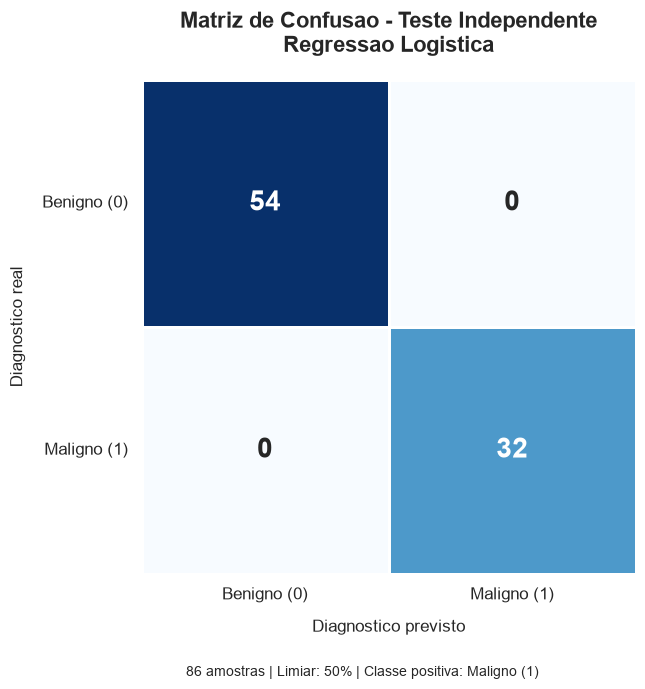


Grafico salvo em:
c:\Users\Cliente\Projetos\tech-challenge-fase1\reports\figures\10_matriz_confusao_final_teste.png

Matriz de confusao final gerada com sucesso!


In [27]:

# ETAPA 6 - PASSO 24
# Visualizacao da matriz de confusao final

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

print("=== MATRIZ DE CONFUSAO FINAL ===")

# 1. Verificar a matriz previamente calculada
assert matriz_teste.shape == (2, 2)
assert matriz_teste.sum() == 86

# 2. Confirmar que a matriz corresponde
# as previsoes da avaliacao independente
matriz_verificacao = confusion_matrix(
    y_test,
    previsoes_teste,
    labels=[0, 1]
)

np.testing.assert_array_equal(
    matriz_teste,
    matriz_verificacao
)

# 3. Recuperar os quatro resultados
vn, fp, fn, vp = matriz_teste.ravel()

print("\nVerdadeiros negativos:", vn)
print("Falsos positivos:", fp)
print("Falsos negativos:", fn)
print("Verdadeiros positivos:", vp)

# 4. Identificar a raiz do projeto
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# 5. Preparar a pasta de figuras
pasta_figuras = raiz / "reports" / "figures"

pasta_figuras.mkdir(
    parents=True,
    exist_ok=True
)

# 6. Definir o estilo do grafico
sns.set_theme(
    style="white",
    font_scale=1.1
)

# 7. Criar a figura
fig, ax = plt.subplots(
    figsize=(9, 7)
)

# 8. Construir o mapa de calor
sns.heatmap(
    matriz_teste,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    linewidths=2,
    linecolor="white",
    square=True,
    xticklabels=[
        "Benigno (0)",
        "Maligno (1)"
    ],
    yticklabels=[
        "Benigno (0)",
        "Maligno (1)"
    ],
    annot_kws={
        "size": 20,
        "weight": "bold"
    },
    ax=ax
)

# 9. Configurar os titulos
ax.set_title(
    "Matriz de Confusao - Teste Independente\n"
    "Regressao Logistica",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Diagnostico previsto",
    fontsize=12,
    labelpad=12
)

ax.set_ylabel(
    "Diagnostico real",
    fontsize=12,
    labelpad=12
)

# 10. Ajustar os rotulos
ax.tick_params(
    axis="x",
    rotation=0
)

ax.tick_params(
    axis="y",
    rotation=0
)

# 11. Adicionar informacoes do experimento
fig.text(
    0.5,
    0.02,
    "86 amostras | Limiar: 50% | "
    "Classe positiva: Maligno (1)",
    ha="center",
    fontsize=10
)

fig.tight_layout(
    rect=[0, 0.05, 1, 1]
)

# 12. Definir o nome do arquivo
arquivo_grafico = (
    pasta_figuras /
    "10_matriz_confusao_final_teste.png"
)

# 13. Salvar em alta resolucao
fig.savefig(
    arquivo_grafico,
    dpi=300,
    bbox_inches="tight"
)

# 14. Exibir o grafico
plt.show()

# 15. Validar o arquivo criado
assert arquivo_grafico.is_file()
assert arquivo_grafico.stat().st_size > 0

print("\nGrafico salvo em:")
print(arquivo_grafico)

print("\nMatriz de confusao final gerada com sucesso!")



## Registro estruturado dos resultados finais

Após a avaliação independente do classificador e
a auditoria de integridade, os resultados serão
armazenados em um arquivo JSON.

O registro conterá:
- Modelo e limiar de classificação
- Quantidade de amostras avaliadas
- Distribuição das classes
- Matriz de confusão
- Acurácia
- Precisão
- Recall
- F1-score
- Especificidade

O objetivo é garantir consistência e rastreabilidade
dos resultados utilizados no relatório acadêmico
e na apresentação em vídeo do Tech Challenge.

As métricas serão calculadas a partir das previsões
já realizadas, sem modificar ou treinar novamente
o modelo definitivo.

Os resultados correspondem exclusivamente ao
conjunto de teste do experimento e não representam
validação clínica.


In [28]:

# ETAPA 6 - PASSO 25
# Registro oficial das metricas finais

import json
import numpy as np

from pathlib import Path

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=== REGISTRO DAS METRICAS FINAIS ===")

# 1. Identificar a raiz do projeto
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# 2. Recuperar a decisao metodologica
arquivo_decisao = (
    raiz / "reports" / "decisao_modelo.json"
)

with arquivo_decisao.open(
    "r",
    encoding="utf-8"
) as arquivo:
    decisao_registrada = json.load(arquivo)

# 3. Confirmar a configuracao selecionada
assert decisao_registrada["modelo"] == "Regressao Logistica"
assert decisao_registrada["limiar"] == 0.50

# 4. Verificar os dados da avaliacao
assert len(y_test) == 86
assert len(previsoes_teste) == 86

# 5. Recuperar a matriz de confusao
matriz_final = confusion_matrix(
    y_test,
    previsoes_teste,
    labels=[0, 1]
)

# Confirmar que corresponde a avaliacao anterior
np.testing.assert_array_equal(
    matriz_final,
    matriz_teste
)

vn, fp, fn, vp = matriz_final.ravel()

# 6. Calcular novamente as metricas
acuracia = accuracy_score(
    y_test,
    previsoes_teste
)

precisao = precision_score(
    y_test,
    previsoes_teste,
    zero_division=0
)

recall = recall_score(
    y_test,
    previsoes_teste,
    zero_division=0
)

f1 = f1_score(
    y_test,
    previsoes_teste,
    zero_division=0
)

especificidade = (
    vn / (vn + fp)
)

# 7. Organizar os resultados
metricas_finais = {
    "projeto": "Tech Challenge - Fase 1",
    "dataset": "Breast Cancer Wisconsin Diagnostic",
    "tipo_avaliacao": "Teste independente reservado",

    "modelo": {
        "algoritmo": decisao_registrada["modelo"],
        "limiar": decisao_registrada["limiar"],
        "classe_positiva": 1,
        "descricao_classe_positiva": "Maligno"
    },

    "dados": {
        "total_dataset": 569,
        "desenvolvimento": 483,
        "teste": int(len(y_test)),
        "caracteristicas": int(X_test.shape[1]),
        "benignos_teste": int(vn + fp),
        "malignos_teste": int(fn + vp)
    },

    "matriz_confusao": {
        "verdadeiros_negativos": int(vn),
        "falsos_positivos": int(fp),
        "falsos_negativos": int(fn),
        "verdadeiros_positivos": int(vp)
    },

    "metricas_percentuais": {
        "acuracia": round(float(acuracia * 100), 2),
        "precisao": round(float(precisao * 100), 2),
        "recall": round(float(recall * 100), 2),
        "f1_score": round(float(f1 * 100), 2),
        "especificidade": round(
            float(especificidade * 100), 2
        )
    },

    "limitacoes": (
        "Resultados observados em um unico conjunto "
        "de teste de 86 amostras. Nao constituem "
        "garantia de generalizacao nem validacao clinica."
    )
}

# 8. Definir o arquivo de saida
arquivo_metricas = (
    raiz / "reports" / "metricas_finais_teste.json"
)

# 9. Salvar as informacoes
with arquivo_metricas.open(
    "w",
    encoding="utf-8"
) as arquivo:
    json.dump(
        metricas_finais,
        arquivo,
        indent=4,
        ensure_ascii=False
    )

# 10. Validar a persistencia
assert arquivo_metricas.is_file()

with arquivo_metricas.open(
    "r",
    encoding="utf-8"
) as arquivo:
    metricas_recuperadas = json.load(arquivo)

assert metricas_recuperadas == metricas_finais

assert (
    metricas_recuperadas["dados"]["teste"] == 86
)

assert (
    sum(
        metricas_recuperadas["matriz_confusao"].values()
    ) == 86
)

# 11. Apresentar um resumo
print("\n=== MODELO ===")
print(metricas_finais["modelo"]["algoritmo"])
print("Limiar:", metricas_finais["modelo"]["limiar"])

print("\n=== RESULTADOS FINAIS ===")

for nome, valor in (
    metricas_finais["metricas_percentuais"].items()
):
    print(f"{nome}: {valor:.2f}%")

print("\n=== MATRIZ DE CONFUSAO ===")
print(matriz_final)

print("\nArquivo salvo em:")
print(arquivo_metricas)

print("\nRegistro das metricas concluido com sucesso!")


=== REGISTRO DAS METRICAS FINAIS ===

=== MODELO ===
Regressao Logistica
Limiar: 0.5

=== RESULTADOS FINAIS ===
acuracia: 100.00%
precisao: 100.00%
recall: 100.00%
f1_score: 100.00%
especificidade: 100.00%

=== MATRIZ DE CONFUSAO ===
[[54  0]
 [ 0 32]]

Arquivo salvo em:
c:\Users\Cliente\Projetos\tech-challenge-fase1\reports\metricas_finais_teste.json

Registro das metricas concluido com sucesso!



# Tech Challenge FIAP - Fase 1

## Etapa 7 - Interpretabilidade da Inteligência Artificial

### Objetivo

Investigar quais características morfológicas
influenciam as classificações realizadas pelo
modelo definitivo de Regressão Logística.

A análise será dividida em:

1. Recuperação do modelo definitivo.
2. Análise dos coeficientes da Regressão Logística.
3. Aplicação da metodologia SHAP.
4. Identificação das características mais influentes.
5. Explicação de previsões individuais.
6. Discussão das limitações da interpretabilidade.

### Metodologia

Será utilizado o modelo previamente treinado
com 483 amostras de desenvolvimento.

O modelo e o limiar de classificação permanecerão
inalterados.

As explicações serão utilizadas para compreender
o comportamento matemático do classificador.

Os resultados não constituem explicações causais,
conclusões médicas ou validação clínica.


In [29]:

# ETAPA 7 - PASSO 26
# Interpretabilidade da Regressao Logistica

import joblib
import numpy as np
import pandas as pd

from pathlib import Path

print("=== INTERPRETABILIDADE DO MODELO ===")

# 1. Localizar a raiz do projeto
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# 2. Localizar o arquivo definitivo
arquivo_modelo = (
    raiz / "models" / "modelo_final_logistica.joblib"
)

assert arquivo_modelo.is_file()

# 3. Recuperar o artefato
artefato = joblib.load(arquivo_modelo)

# 4. Recuperar seus componentes
pipeline = artefato["pipeline"]

limiar = artefato["limiar"]

caracteristicas = artefato["colunas"]

# 5. Recuperar o padronizador e classificador
padronizador = pipeline.named_steps[
    "padronizacao"
]

classificador = pipeline.named_steps[
    "classificador"
]

# 6. Verificar a estrutura
assert len(caracteristicas) == 30
assert pipeline.n_features_in_ == 30
assert limiar == 0.50

assert list(classificador.classes_) == [0, 1]
assert classificador.coef_.shape == (1, 30)

assert "id" not in caracteristicas
assert "diagnosis" not in caracteristicas

print("\nModelo recuperado com sucesso!")
print("Algoritmo: Regressao Logistica")
print("Limiar:", limiar)
print("Caracteristicas:", len(caracteristicas))

# 7. Recuperar os coeficientes
coeficientes = classificador.coef_[0]

assert np.isfinite(coeficientes).all()

# 8. Construir a tabela de interpretabilidade
tabela_coeficientes = pd.DataFrame({
    "Caracteristica": caracteristicas,
    "Coeficiente": coeficientes
})

# 9. Calcular o valor absoluto
tabela_coeficientes["Magnitude"] = (
    tabela_coeficientes["Coeficiente"].abs()
)

# 10. Ordenar pela magnitude dos coeficientes
tabela_coeficientes = (
    tabela_coeficientes
    .sort_values(
        "Magnitude",
        ascending=False
    )
    .reset_index(drop=True)
)

# 11. Exibir as dez maiores magnitudes
print("\n=== DEZ MAIORES COEFICIENTES ===")

display(
    tabela_coeficientes.head(10).round(4)
)

# 12. Apresentar um resumo
print("\nCoeficientes positivos:",
      int((coeficientes > 0).sum()))

print("Coeficientes negativos:",
      int((coeficientes < 0).sum()))

print("\nAnalise inicial concluida!")
print("O modelo definitivo nao foi modificado.")


=== INTERPRETABILIDADE DO MODELO ===

Modelo recuperado com sucesso!
Algoritmo: Regressao Logistica
Limiar: 0.5
Caracteristicas: 30

=== DEZ MAIORES COEFICIENTES ===


,Caracteristica,Coeficiente,Magnitude
0,texture_worst,1.4110,1.4110
1,radius_se,1.3048,1.3048
2,radius_worst,0.9647,0.9647
3,concave_points_mean,0.9546,0.9546
4,area_se,0.9471,0.9471
5,area_worst,0.9296,0.9296
6,symmetry_worst,0.8866,0.8866
7,concave_points_worst,0.8385,0.8385
8,concavity_worst,0.8172,0.8172
9,perimeter_worst,0.7416,0.7416



Coeficientes positivos: 21
Coeficientes negativos: 9

Analise inicial concluida!
O modelo definitivo nao foi modificado.



## Visualização dos coeficientes da Regressão Logística

Nesta análise, serão apresentados graficamente os
30 coeficientes aprendidos pelo modelo definitivo.

O gráfico permitirá visualizar:

- Características com coeficientes positivos.
- Características com coeficientes negativos.
- Magnitude dos coeficientes padronizados.
- Distribuição das características no modelo.

Os coeficientes serão obtidos diretamente do
pipeline persistido, sem realizar novo treinamento.

A interpretação dos coeficientes considera que
as características foram padronizadas.

Os resultados não representam relações causais
nem comprovam importância clínica das variáveis.


=== VISUALIZACAO DOS COEFICIENTES ===


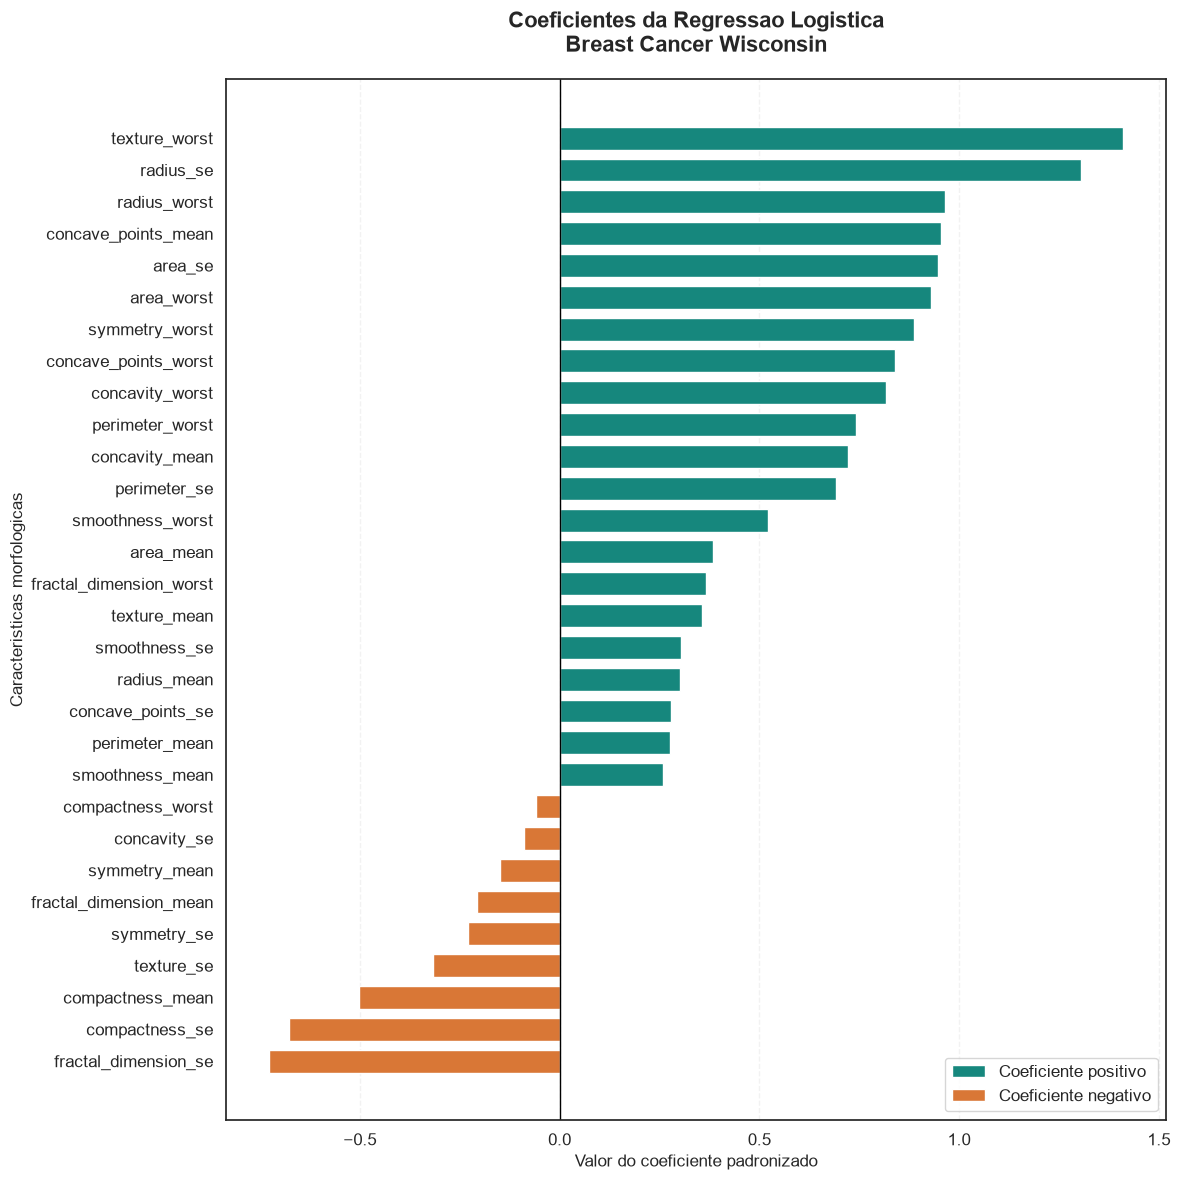


=== RESUMO ===
Coeficientes positivos: 21
Coeficientes negativos: 9

Grafico salvo em:
c:\Users\Cliente\Projetos\tech-challenge-fase1\reports\figures\11_coeficientes_regressao_logistica.png

Visualizacao concluida com sucesso!


In [30]:

# ETAPA 7 - PASSO 27
# Visualizacao dos coeficientes da Regressao Logistica

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.patches import Patch

print("=== VISUALIZACAO DOS COEFICIENTES ===")

# 1. Localizar a raiz do projeto
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# 2. Localizar o modelo definitivo
arquivo_modelo = (
    raiz / "models" / "modelo_final_logistica.joblib"
)

assert arquivo_modelo.is_file()

# 3. Carregar o modelo
artefato = joblib.load(arquivo_modelo)

pipeline = artefato["pipeline"]
caracteristicas = artefato["colunas"]

# 4. Recuperar o classificador
classificador = pipeline.named_steps[
    "classificador"
]

# 5. Recuperar os coeficientes
coeficientes = classificador.coef_[0]

assert len(coeficientes) == 30
assert len(caracteristicas) == 30
assert np.isfinite(coeficientes).all()

# 6. Construir a tabela
tabela = pd.DataFrame({
    "Caracteristica": caracteristicas,
    "Coeficiente": coeficientes
})

# 7. Ordenar pelo valor do coeficiente
tabela = tabela.sort_values(
    "Coeficiente",
    ascending=True
)

# 8. Definir as cores
cores = [
    "#16877D" if valor >= 0 else "#D97736"
    for valor in tabela["Coeficiente"]
]

# 9. Criar o grafico
fig, ax = plt.subplots(
    figsize=(12, 12)
)

ax.barh(
    tabela["Caracteristica"],
    tabela["Coeficiente"],
    color=cores,
    height=0.72
)

# 10. Criar a linha de referencia
ax.axvline(
    x=0,
    color="black",
    linewidth=1
)

# 11. Configurar titulos
ax.set_title(
    "Coeficientes da Regressao Logistica\n"
    "Breast Cancer Wisconsin",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Valor do coeficiente padronizado",
    fontsize=12
)

ax.set_ylabel(
    "Caracteristicas morfologicas",
    fontsize=12
)

# 12. Criar a legenda
legenda = [
    Patch(
        facecolor="#16877D",
        label="Coeficiente positivo"
    ),
    Patch(
        facecolor="#D97736",
        label="Coeficiente negativo"
    )
]

ax.legend(
    handles=legenda,
    loc="lower right"
)

# 13. Configurar a grade
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

# 14. Ajustar o layout
fig.tight_layout()

# 15. Preparar o diretorio
pasta_figuras = raiz / "reports" / "figures"

pasta_figuras.mkdir(
    parents=True,
    exist_ok=True
)

# 16. Definir o nome do arquivo
arquivo_grafico = (
    pasta_figuras /
    "11_coeficientes_regressao_logistica.png"
)

# 17. Salvar o grafico
fig.savefig(
    arquivo_grafico,
    dpi=300,
    bbox_inches="tight"
)

# 18. Exibir o grafico
plt.show()

# 19. Validar o resultado
assert arquivo_grafico.is_file()
assert arquivo_grafico.stat().st_size > 0

print("\n=== RESUMO ===")

print(
    "Coeficientes positivos:",
    int((coeficientes > 0).sum())
)

print(
    "Coeficientes negativos:",
    int((coeficientes < 0).sum())
)

print("\nGrafico salvo em:")
print(arquivo_grafico)

print("\nVisualizacao concluida com sucesso!")



## Interpretabilidade com SHAP

Nesta etapa, será aplicado o método SHAP
para explicar as previsões da Regressão Logística.

Será utilizado o LinearExplainer, adequado
para classificadores lineares.

As características serão transformadas pelo
StandardScaler previamente ajustado.

O ponto de referência será o vetor de zeros
no espaço padronizado, correspondente às
médias do conjunto de desenvolvimento.

As explicações serão calculadas para as
86 amostras do conjunto de teste.

Serão verificadas:
- Dimensões dos valores SHAP.
- Consistência matemática das explicações.
- Características com maiores contribuições médias.
- Correspondência com as previsões do modelo.

Os valores SHAP serão interpretados na escala
de logaritmo das chances (log-odds).

A abordagem adotada considera as características
independentes na atribuição das contribuições,
não representando relações causais ou clínicas.


In [31]:

# ETAPA 7 - PASSO 28
# Interpretabilidade com SHAP - LinearExplainer

import shap
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from scipy.special import expit

print("=== INTERPRETABILIDADE COM SHAP ===")

print("Versao do SHAP:", shap.__version__)

# 1. Localizar o projeto
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# 2. Recuperar o modelo definitivo
arquivo_modelo = (
    raiz / "models" / "modelo_final_logistica.joblib"
)

artefato_shap = joblib.load(arquivo_modelo)

pipeline_shap = artefato_shap["pipeline"]
colunas_shap = list(artefato_shap["colunas"])

# 3. Recuperar os componentes treinados
padronizador_shap = pipeline_shap.named_steps[
    "padronizacao"
]

classificador_shap = pipeline_shap.named_steps[
    "classificador"
]

# 4. Preparar o conjunto de teste original
# X_test foi criado anteriormente neste notebook
assert X_test.shape == (86, 30)
assert list(X_test.columns) == colunas_shap

X_teste_original = X_test.copy()

# 5. Aplicar o padronizador ja treinado
# Nao executar fit() ou fit_transform()
X_teste_padronizado = pd.DataFrame(
    padronizador_shap.transform(X_teste_original),
    columns=colunas_shap,
    index=X_teste_original.index
)

assert X_teste_padronizado.shape == (86, 30)

print("\nDados padronizados: OK")

# 6. Definir a referencia no espaco padronizado
# Zero corresponde a media do desenvolvimento
referencia_shap = np.zeros((1, 30))

# 7. Criar o explicador
mascara_shap = shap.maskers.Independent(
    referencia_shap
)

explicador_shap = shap.LinearExplainer(
    classificador_shap,
    mascara_shap
)

print("LinearExplainer criado com sucesso!")

# 8. Calcular os valores SHAP
valores_shap = explicador_shap.shap_values(
    X_teste_padronizado
)

valores_shap = np.asarray(valores_shap)

# 9. Validar as dimensoes
assert valores_shap.shape == (86, 30)
assert np.isfinite(valores_shap).all()

print("\nDimensoes SHAP:", valores_shap.shape)

# 10. Recuperar o valor de referencia
valor_base_shap = float(
    np.asarray(
        explicador_shap.expected_value
    ).item()
)

# 11. Reconstruir a saida do modelo
# Na escala log-odds
log_odds_shap = (
    valor_base_shap +
    valores_shap.sum(axis=1)
)

log_odds_modelo = (
    classificador_shap.decision_function(
        X_teste_padronizado
    )
)

np.testing.assert_allclose(
    log_odds_shap,
    log_odds_modelo,
    rtol=1e-7,
    atol=1e-7
)

print("Consistencia matematica SHAP: OK")

# 12. Converter as saidas para probabilidades
probabilidades_shap = expit(log_odds_shap)

probabilidades_modelo = (
    pipeline_shap.predict_proba(
        X_teste_original
    )[:, 1]
)

np.testing.assert_allclose(
    probabilidades_shap,
    probabilidades_modelo,
    rtol=1e-7,
    atol=1e-7
)

print("Probabilidades preservadas: OK")

# 13. Calcular a contribuicao absoluta media
importancia_shap = pd.DataFrame({
    "Caracteristica": colunas_shap,
    "SHAP_medio_absoluto": (
        np.abs(valores_shap).mean(axis=0)
    )
})

# 14. Ordenar as caracteristicas
importancia_shap = (
    importancia_shap
    .sort_values(
        "SHAP_medio_absoluto",
        ascending=False
    )
    .reset_index(drop=True)
)

# 15. Mostrar as dez principais caracteristicas
print("\n=== DEZ MAIORES CONTRIBUICOES SHAP ===")

display(
    importancia_shap.head(10).round(4)
)

# 16. Resumo
print("\n=== VALIDACAO FINAL ===")
print("Amostras explicadas:", len(valores_shap))
print("Caracteristicas:", valores_shap.shape[1])
print("Modelo original preservado: OK")

print("\nAnalise SHAP inicial concluida!")


=== INTERPRETABILIDADE COM SHAP ===
Versao do SHAP: 0.54.1

Dados padronizados: OK
LinearExplainer criado com sucesso!

Dimensoes SHAP: (86, 30)
Consistencia matematica SHAP: OK
Probabilidades preservadas: OK

=== DEZ MAIORES CONTRIBUICOES SHAP ===


c:\Users\Cliente\Projetos\tech-challenge-fase1\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


,Caracteristica,SHAP_medio_absoluto
0,texture_worst,1.2021
1,radius_worst,0.8595
2,radius_se,0.8284
3,concave_points_mean,0.7746
4,area_worst,0.7593
5,concave_points_worst,0.7406
6,perimeter_worst,0.6510
7,concavity_worst,0.6444
8,symmetry_worst,0.5695
9,concavity_mean,0.5547



=== VALIDACAO FINAL ===
Amostras explicadas: 86
Caracteristicas: 30
Modelo original preservado: OK

Analise SHAP inicial concluida!



## Importância global das características com SHAP

A análise de importância global busca identificar
quais características apresentaram maiores
contribuições absolutas médias nas 86 amostras.

Para cada variável, calcula-se a média dos
valores absolutos de suas contribuições SHAP.

Serão apresentadas as dez características
mais influentes segundo essa medida.

O gráfico será salvo em alta resolução para
documentação do Tech Challenge.

Os resultados são expressos em unidades de
log-odds e dependem do modelo, do conjunto
analisado e da referência utilizada.

A importância global não estabelece causalidade
nem representa importância clínica.


=== IMPORTANCIA GLOBAL SHAP ===
Valores SHAP validados: OK


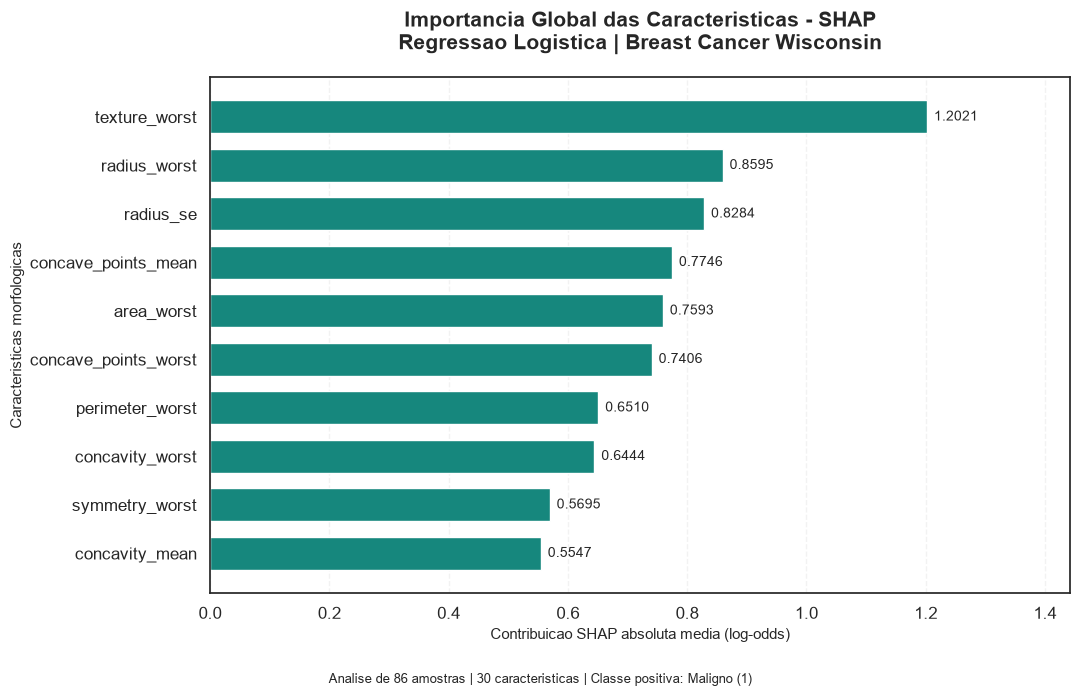


=== DEZ CARACTERISTICAS PRINCIPAIS ===


,Caracteristica,Importancia_SHAP
0,texture_worst,1.2021
1,radius_worst,0.8595
2,radius_se,0.8284
3,concave_points_mean,0.7746
4,area_worst,0.7593
5,concave_points_worst,0.7406
6,perimeter_worst,0.6510
7,concavity_worst,0.6444
8,symmetry_worst,0.5695
9,concavity_mean,0.5547



Caracteristica mais influente:
texture_worst

Grafico salvo em:
c:\Users\Cliente\Projetos\tech-challenge-fase1\reports\figures\12_importancia_global_shap.png

Grafico SHAP gerado com sucesso!


In [32]:

# ETAPA 7 - PASSO 29
# Grafico de importancia global SHAP

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

print("=== IMPORTANCIA GLOBAL SHAP ===")

# 1. Validar os resultados anteriores
assert valores_shap.shape == (86, 30)
assert len(colunas_shap) == 30
assert np.isfinite(valores_shap).all()

print("Valores SHAP validados: OK")

# 2. Calcular a contribuicao absoluta media
tabela_importancia = pd.DataFrame({
    "Caracteristica": colunas_shap,
    "Importancia_SHAP": (
        np.abs(valores_shap).mean(axis=0)
    )
})

# 3. Ordenar as caracteristicas
tabela_importancia = (
    tabela_importancia
    .sort_values(
        "Importancia_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

# 4. Selecionar as dez principais
top10 = tabela_importancia.head(10).copy()

# 5. Inverter a ordem para o grafico horizontal
dados_grafico = top10.iloc[::-1]

# 6. Criar a figura
fig, ax = plt.subplots(
    figsize=(11, 7)
)

# 7. Construir as barras
barras = ax.barh(
    dados_grafico["Caracteristica"],
    dados_grafico["Importancia_SHAP"],
    color="#16877D",
    height=0.68
)

# 8. Adicionar os valores numericos
ax.bar_label(
    barras,
    fmt="%.4f",
    padding=5,
    fontsize=10
)

# 9. Configurar o titulo
ax.set_title(
    "Importancia Global das Caracteristicas - SHAP\n"
    "Regressao Logistica | Breast Cancer Wisconsin",
    fontsize=15,
    fontweight="bold",
    pad=20
)

# 10. Configurar os eixos
ax.set_xlabel(
    "Contribuicao SHAP absoluta media (log-odds)",
    fontsize=11
)

ax.set_ylabel(
    "Caracteristicas morfologicas",
    fontsize=11
)

# 11. Ajustar o limite do eixo horizontal
maior_valor = top10["Importancia_SHAP"].max()

ax.set_xlim(
    0,
    maior_valor * 1.20
)

# 12. Adicionar a grade
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

# 13. Adicionar informacao sobre o estudo
fig.text(
    0.5,
    0.01,
    "Analise de 86 amostras | 30 caracteristicas | "
    "Classe positiva: Maligno (1)",
    ha="center",
    fontsize=9
)

fig.tight_layout(
    rect=[0, 0.04, 1, 1]
)

# 14. Localizar a raiz do projeto
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# 15. Preparar a pasta de figuras
pasta_figuras = raiz / "reports" / "figures"

pasta_figuras.mkdir(
    parents=True,
    exist_ok=True
)

# 16. Definir o arquivo
arquivo_grafico = (
    pasta_figuras /
    "12_importancia_global_shap.png"
)

# 17. Salvar em alta resolucao
fig.savefig(
    arquivo_grafico,
    dpi=300,
    bbox_inches="tight"
)

# 18. Exibir
plt.show()

# 19. Validar o arquivo
assert arquivo_grafico.is_file()
assert arquivo_grafico.stat().st_size > 0

# 20. Apresentar os resultados
print("\n=== DEZ CARACTERISTICAS PRINCIPAIS ===")

display(top10.round(4))

print("\nCaracteristica mais influente:")
print(top10.iloc[0]["Caracteristica"])

print("\nGrafico salvo em:")
print(arquivo_grafico)

print("\nGrafico SHAP gerado com sucesso!")



## Análise da distribuição das contribuições SHAP

O gráfico Beeswarm apresenta a distribuição das
contribuições das características nas 86 amostras
do conjunto de teste.

Cada ponto representa uma amostra.

O eixo horizontal representa a contribuição SHAP
na escala de log-odds.

A cor representa o valor da característica
padronizada, variando de baixo para alto.

Serão apresentadas as 15 características
com maiores contribuições absolutas médias.

Essa análise permite identificar padrões
de contribuição e diferenças entre amostras.

As explicações são associativas, dependem
da referência utilizada e não constituem
evidência de causalidade clínica.


=== ANALISE SHAP BEESWARM ===
Valores SHAP verificados: OK
Explicacoes matematicamente consistentes: OK


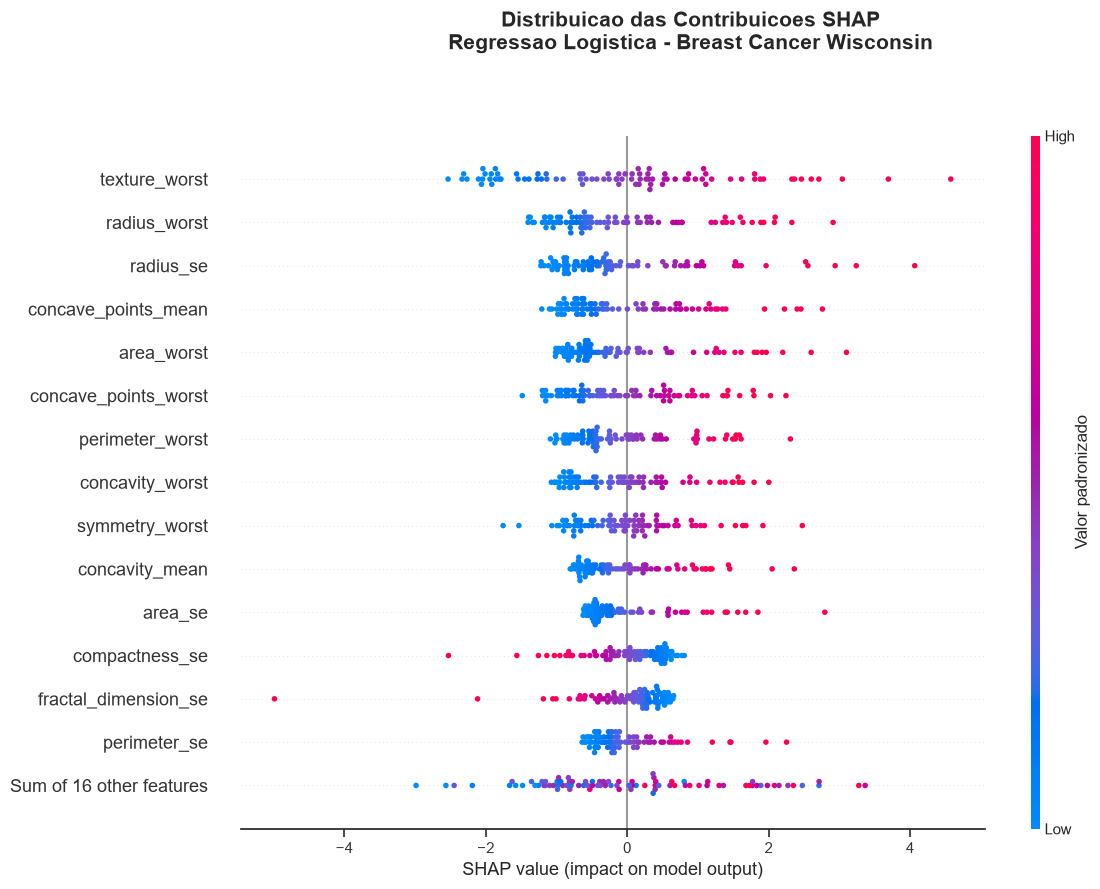


=== RESUMO DA ANALISE ===
Amostras analisadas: 86
Caracteristicas totais: 30
Caracteristicas exibidas: 15

Grafico salvo em:
c:\Users\Cliente\Projetos\tech-challenge-fase1\reports\figures\13_shap_beeswarm.png

Beeswarm gerado com sucesso!


In [33]:

# ETAPA 7 - PASSO 30
# Visualizacao SHAP Beeswarm

import shap
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

print("=== ANALISE SHAP BEESWARM ===")

# 1. Verificar os resultados anteriores
assert valores_shap.shape == (86, 30)
assert X_teste_padronizado.shape == (86, 30)
assert len(colunas_shap) == 30

assert np.isfinite(valores_shap).all()

print("Valores SHAP verificados: OK")

# 2. Criar os valores de referencia
# Um valor base para cada amostra
valores_base = np.full(
    shape=86,
    fill_value=valor_base_shap
)

# 3. Criar o objeto Explanation
# Necessario para os graficos SHAP modernos
explicacoes_shap = shap.Explanation(
    values=valores_shap,
    base_values=valores_base,
    data=X_teste_padronizado.to_numpy(),
    feature_names=colunas_shap
)

# 4. Verificar a estrutura
assert explicacoes_shap.values.shape == (86, 30)
assert len(explicacoes_shap.base_values) == 86

# 5. Validar a propriedade de aditividade
log_odds_reconstruido = (
    explicacoes_shap.base_values
    + explicacoes_shap.values.sum(axis=1)
)

np.testing.assert_allclose(
    log_odds_reconstruido,
    log_odds_modelo,
    rtol=1e-7,
    atol=1e-7
)

print("Explicacoes matematicamente consistentes: OK")

# 6. Construir o Beeswarm
shap.plots.beeswarm(
    explicacoes_shap,
    max_display=15,
    show=False,
    plot_size=(12, 9),
    color_bar_label="Valor padronizado"
)

# 7. Recuperar a figura
fig = plt.gcf()

fig.suptitle(
    "Distribuicao das Contribuicoes SHAP\n"
    "Regressao Logistica - Breast Cancer Wisconsin",
    fontsize=15,
    fontweight="bold",
    y=1.02
)

# 8. Localizar a raiz do projeto
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# 9. Preparar a pasta de figuras
pasta_figuras = raiz / "reports" / "figures"

pasta_figuras.mkdir(
    parents=True,
    exist_ok=True
)

# 10. Definir o arquivo final
arquivo_beeswarm = (
    pasta_figuras /
    "13_shap_beeswarm.png"
)

# 11. Salvar o grafico em alta resolucao
fig.savefig(
    arquivo_beeswarm,
    dpi=300,
    bbox_inches="tight"
)

# 12. Exibir o grafico
plt.show()

# 13. Validar o arquivo
assert arquivo_beeswarm.is_file()
assert arquivo_beeswarm.stat().st_size > 0

# 14. Apresentar o resumo
print("\n=== RESUMO DA ANALISE ===")

print(
    "Amostras analisadas:",
    explicacoes_shap.values.shape[0]
)

print(
    "Caracteristicas totais:",
    explicacoes_shap.values.shape[1]
)

print("Caracteristicas exibidas: 15")

print("\nGrafico salvo em:")
print(arquivo_beeswarm)

print("\nBeeswarm gerado com sucesso!")



## Explicação individual de uma previsão com SHAP

Nesta etapa, será analisada uma previsão individual
realizada pelo modelo definitivo de Regressão Logística.

Será selecionada a primeira amostra com diagnóstico
maligno no conjunto independente de teste.

O gráfico Waterfall permitirá identificar:

- O valor de referência do modelo.
- As características que aumentam a saída.
- As características que diminuem a saída.
- A contribuição de cada variável.
- A saída final e a probabilidade correspondente.

Os valores SHAP são expressos em log-odds.

A explicação representa a decomposição matemática
da previsão e não constitui diagnóstico médico
ou interpretação causal das características.


=== EXPLICACAO INDIVIDUAL SHAP ===

=== AMOSTRA SELECIONADA ===
Posicao no conjunto: 0
Indice do DataFrame: 162
Diagnostico real: Maligno
Diagnostico previsto: Maligno
Probabilidade estimada de malignidade: 100.00%
Limiar utilizado: 0.50


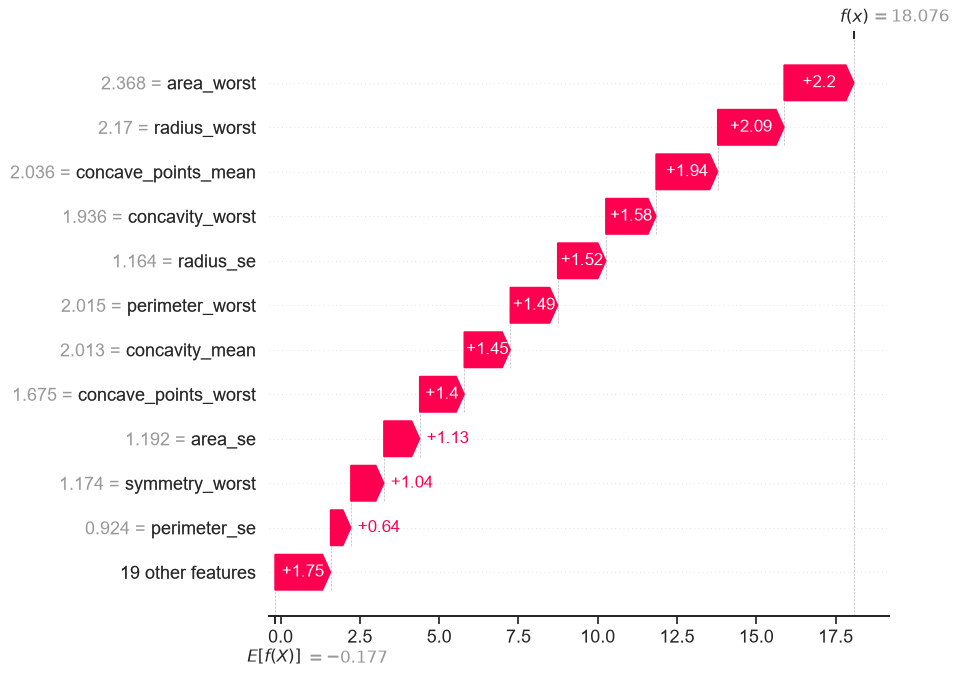


=== DEZ MAIORES CONTRIBUICOES ===


,Caracteristica,Valor_SHAP,Magnitude
0,area_worst,2.2017,2.2017
1,radius_worst,2.0938,2.0938
2,concave_points_mean,1.9440,1.9440
3,concavity_worst,1.5824,1.5824
4,radius_se,1.5190,1.5190
5,perimeter_worst,1.4942,1.4942
6,concavity_mean,1.4520,1.4520
7,concave_points_worst,1.4044,1.4044
8,area_se,1.1294,1.1294
9,symmetry_worst,1.0408,1.0408



=== VALIDACAO FINAL ===
Reconstrucao da probabilidade: OK
Modelo definitivo preservado: OK

Grafico salvo em:
c:\Users\Cliente\Projetos\tech-challenge-fase1\reports\figures\14_shap_waterfall_maligno.png

Passo 31 concluido com sucesso!


In [34]:

# ETAPA 7 - PASSO 31
# Explicacao individual com SHAP Waterfall

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.special import expit

print("=== EXPLICACAO INDIVIDUAL SHAP ===")

# 1. Validar as estruturas anteriores
assert explicacoes_shap.values.shape == (86, 30)
assert X_teste_original.shape == (86, 30)
assert len(y_test) == 86

# 2. Selecionar a primeira amostra maligna
# A escolha segue a ordem do conjunto de teste
posicoes_malignas = np.flatnonzero(
    np.asarray(y_test) == 1
)

assert len(posicoes_malignas) > 0

posicao = int(posicoes_malignas[0])

# 3. Recuperar a amostra selecionada
amostra = X_teste_original.iloc[[posicao]]

indice_amostra = X_teste_original.index[posicao]

diagnostico_real = int(
    np.asarray(y_test)[posicao]
)

# 4. Calcular a probabilidade original
probabilidade = float(
    pipeline_shap.predict_proba(amostra)[0, 1]
)

# 5. Recuperar a previsao
limiar = float(artefato_shap["limiar"])

previsao = int(
    probabilidade >= limiar
)

# 6. Recuperar a explicacao individual
explicacao_individual = explicacoes_shap[
    posicao
]

# 7. Validar a reconstrucao matematica
valor_base = float(
    explicacao_individual.base_values
)

contribuicoes = explicacao_individual.values

log_odds_final = (
    valor_base + contribuicoes.sum()
)

probabilidade_reconstruida = float(
    expit(log_odds_final)
)

np.testing.assert_allclose(
    probabilidade,
    probabilidade_reconstruida,
    atol=1e-7,
    rtol=1e-7
)

print("\n=== AMOSTRA SELECIONADA ===")

print("Posicao no conjunto:", posicao)
print("Indice do DataFrame:", indice_amostra)

print(
    "Diagnostico real:",
    "Maligno" if diagnostico_real == 1
    else "Benigno"
)

print(
    "Diagnostico previsto:",
    "Maligno" if previsao == 1
    else "Benigno"
)

print(
    f"Probabilidade estimada de malignidade: "
    f"{probabilidade * 100:.2f}%"
)

print(f"Limiar utilizado: {limiar:.2f}")

# 8. Construir o grafico Waterfall
ax = shap.plots.waterfall(
    explicacao_individual,
    max_display=12,
    show=False
)

# 9. Recuperar a figura
fig = ax.figure

# 10. Localizar a raiz do projeto
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# 11. Preparar o diretorio
pasta_figuras = raiz / "reports" / "figures"

pasta_figuras.mkdir(
    parents=True,
    exist_ok=True
)

# 12. Definir o nome do arquivo
arquivo_waterfall = (
    pasta_figuras /
    "14_shap_waterfall_maligno.png"
)

# 13. Salvar o grafico
fig.savefig(
    arquivo_waterfall,
    dpi=300,
    bbox_inches="tight"
)

# 14. Exibir o grafico
plt.show()

# 15. Validar o arquivo
assert arquivo_waterfall.is_file()
assert arquivo_waterfall.stat().st_size > 0

# 16. Construir a tabela das contribuicoes
tabela_individual = pd.DataFrame({
    "Caracteristica": colunas_shap,
    "Valor_SHAP": contribuicoes,
    "Magnitude": np.abs(contribuicoes)
})

tabela_individual = (
    tabela_individual
    .sort_values(
        "Magnitude",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n=== DEZ MAIORES CONTRIBUICOES ===")

display(
    tabela_individual.head(10).round(4)
)

print("\n=== VALIDACAO FINAL ===")

print(
    "Reconstrucao da probabilidade: OK"
)

print(
    "Modelo definitivo preservado: OK"
)

print("\nGrafico salvo em:")
print(arquivo_waterfall)

print("\nPasso 31 concluido com sucesso!")



## Explicação individual de uma amostra benigna

Será selecionada a primeira amostra com diagnóstico
benigno do conjunto independente de teste.

A análise utilizará o modelo definitivo e as
explicações SHAP calculadas anteriormente.

Serão verificadas:
- A classificação real da amostra.
- A classificação prevista pelo modelo.
- A probabilidade estimada de malignidade.
- As contribuições positivas e negativas.
- A reconstrução matemática da previsão.

Os resultados serão apresentados por meio de um
gráfico Waterfall e uma tabela de contribuições.

A explicação não representa uma avaliação médica.


=== EXPLICACAO SHAP - AMOSTRA BENIGNA ===

=== RESULTADO DA CLASSIFICACAO ===
Indice da amostra: 60
Diagnostico real: Benigno
Diagnostico previsto: Benigno
Probabilidade estimada de malignidade: 0.0064%
Limiar: 0.5
Log-odds: -9.6562


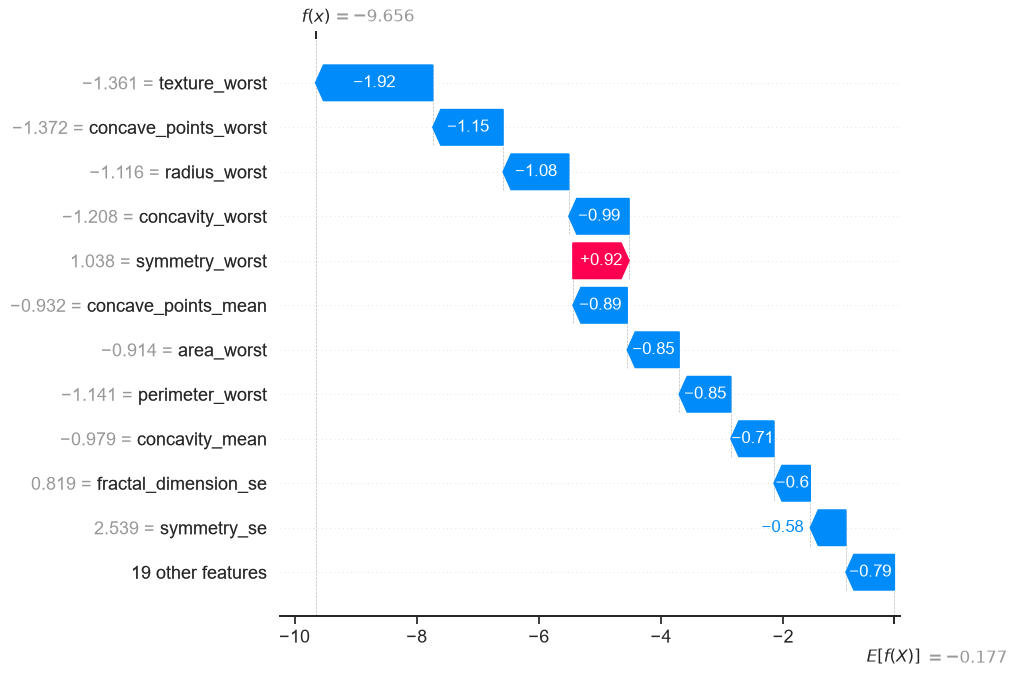


=== DEZ MAIORES CONTRIBUICOES ===


,Caracteristica,Valor_original,Valor_SHAP,Magnitude
0,texture_worst,17.4500,-1.9203,1.9203
1,concave_points_worst,0.0258,-1.1505,1.1505
2,radius_worst,11.0200,-1.0763,1.0763
3,concavity_worst,0.0217,-0.9875,0.9875
4,symmetry_worst,0.3557,0.9202,0.9202
5,concave_points_mean,0.0129,-0.8898,0.8898
6,area_worst,368.6000,-0.8500,0.8500
7,perimeter_worst,69.8600,-0.8462,0.8462
8,concavity_mean,0.0108,-0.7064,0.7064
9,fractal_dimension_se,0.0060,-0.5953,0.5953



=== VALIDACAO FINAL ===
Reconstrucao matematica: OK
Classificacao correta: True
Modelo definitivo preservado: OK

Grafico salvo em:
c:\Users\Cliente\Projetos\tech-challenge-fase1\reports\figures\15_shap_waterfall_benigno.png

Passo 32 concluido com sucesso!
